In [1]:
print("Hello,Predictive Maintenance")

Hello,Predictive Maintenance


In [2]:
import pandas as pd

In [3]:
pd.__version__

'3.0.6'

In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
import os

In [6]:
os.listdir("../data/raw")


['RUL_FD001.txt', 'test_FD001.txt', 'train_FD001.txt']

In [7]:
os.getcwd

<function nt.getcwd()>

In [8]:
os.getcwd()


'C:\\Users\\hp\\predictive-maintenance\\notebooks'

In [9]:
train_path = "../data/raw/train_FD001.txt"

train_df = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None
)

In [10]:
train_df.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [11]:
train_df.shape

(20631, 26)

In [12]:
columns = [
    "unit",
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3",
    "sensor_1",
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_5",
    "sensor_6",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_10",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_16",
    "sensor_17",
    "sensor_18",
    "sensor_19",
    "sensor_20",
    "sensor_21"
]

In [13]:
train_df.columns=columns

In [14]:
train_df.head(6)

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
5,1,6,-0.0043,-0.0001,100.0,518.67,642.10,1584.47,1398.37,14.62,...,521.68,2388.03,8132.85,8.4108,0.03,391,2388,100.0,38.98,23.3669


In [15]:
train_df["unit"].nunique

<bound method IndexOpsMixin.nunique of 0          1
1          1
2          1
3          1
4          1
        ... 
20626    100
20627    100
20628    100
20629    100
20630    100
Name: unit, Length: 20631, dtype: int64>

In [16]:
train_df.groupby("unit")["cycle"].max()

unit
1      192
2      287
3      179
4      189
5      269
      ... 
96     336
97     202
98     156
99     185
100    200
Name: cycle, Length: 100, dtype: int64

In [17]:
cycle_lengths = train_df.groupby("unit")["cycle"].max()

cycle_lengths.describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

In [18]:
train_df.isnull().sum()

unit         0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
dtype: int64

In [19]:
train_df.duplicated().sum()

0

In [20]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
unit,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200


In [21]:
cycle_lengths = train_df.groupby("unit")["cycle"].max()

In [22]:
cycle_lengths.head(10)

unit
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: cycle, dtype: int64

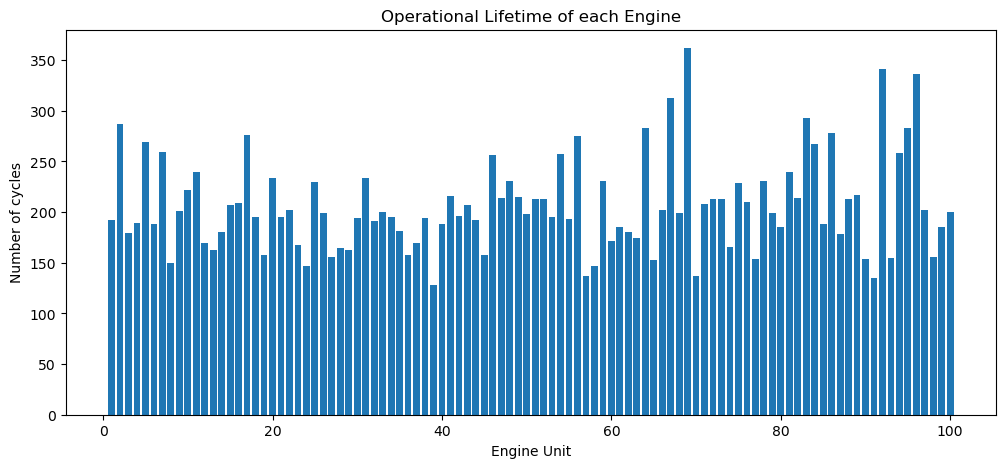

In [23]:
plt.figure(figsize=(12,5))
plt.bar(cycle_lengths.index,cycle_lengths.values)

plt.xlabel("Engine Unit")
plt.ylabel("Number of cycles")
plt.title("Operational Lifetime of each Engine")

plt.show()


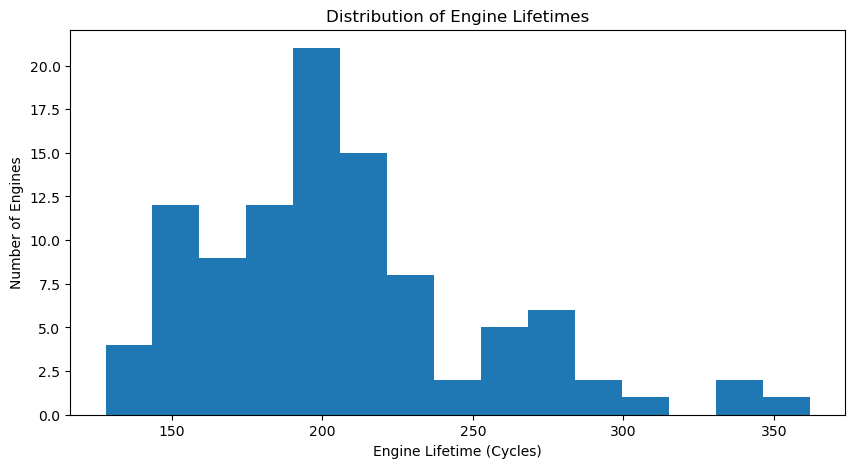

In [24]:
plt.figure(figsize=(10, 5))

plt.hist(
    cycle_lengths,
    bins=15
)

plt.xlabel("Engine Lifetime (Cycles)")
plt.ylabel("Number of Engines")
plt.title("Distribution of Engine Lifetimes")

plt.show()

In [25]:
max_cycles=train_df.groupby("unit")["cycle"].max()
train_df["RUL"]=train_df["unit"].map(max_cycles)-train_df["cycle"]

In [26]:
train_df[["unit","cycle","RUL"]].head(10)

,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


In [27]:
engine_1=train_df[train_df["unit"]==1]

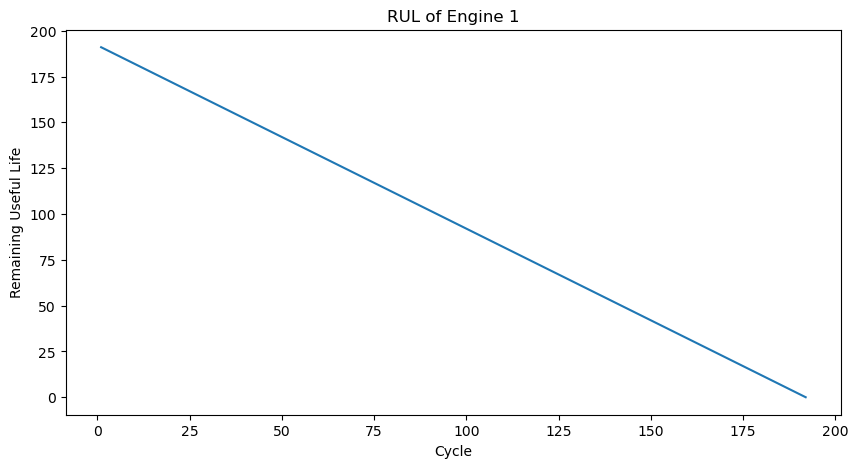

In [28]:
plt.figure(figsize=(10,5))
plt.plot(engine_1["cycle"],engine_1["RUL"])
plt.xlabel("Cycle")
plt.ylabel("Remaining Useful Life")
plt.title("RUL of Engine 1")
plt.show()

In [29]:
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

sensor_cols

['sensor_1',
 'sensor_2',
 'sensor_3',
 'sensor_4',
 'sensor_5',
 'sensor_6',
 'sensor_7',
 'sensor_8',
 'sensor_9',
 'sensor_10',
 'sensor_11',
 'sensor_12',
 'sensor_13',
 'sensor_14',
 'sensor_15',
 'sensor_16',
 'sensor_17',
 'sensor_18',
 'sensor_19',
 'sensor_20',
 'sensor_21']

In [30]:
sensor_std = train_df[sensor_cols].std()

sensor_std.sort_values()

sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.556432e-14
sensor_10    4.660829e-13
sensor_5     3.394700e-12
sensor_1     6.537152e-11
sensor_6     1.388985e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64

In [31]:
train_df[sensor_cols].nunique().sort_values()

sensor_1        1
sensor_19       1
sensor_18       1
sensor_5        1
sensor_16       1
sensor_10       1
sensor_6        2
sensor_17      13
sensor_8       53
sensor_13      56
sensor_20     120
sensor_11     159
sensor_2      310
sensor_12     427
sensor_7      513
sensor_15    1918
sensor_3     3012
sensor_4     4051
sensor_21    4745
sensor_14    6078
sensor_9     6403
dtype: int64

In [32]:
sensor_rul_corr = train_df[sensor_cols + ["RUL"]].corr()["RUL"]

sensor_rul_corr.sort_values()

sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
RUL          1.000000
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64

In [33]:
engine_1 = train_df[train_df["unit"] == 1]

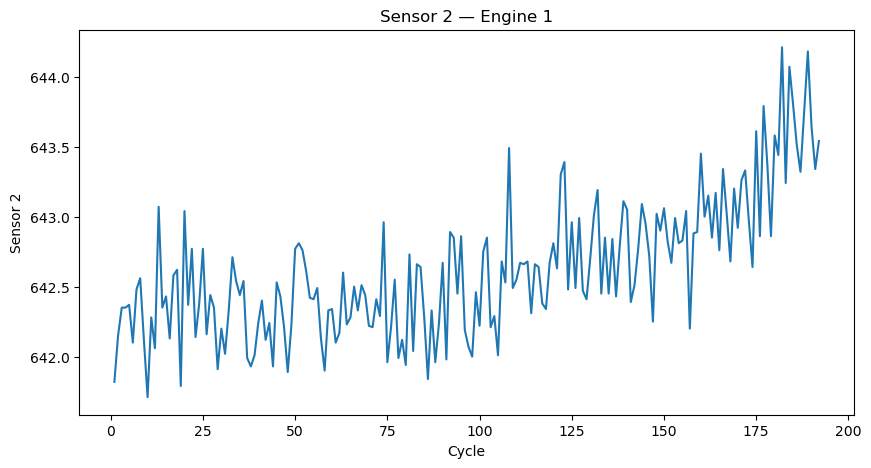

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2"]
)

plt.xlabel("Cycle")
plt.ylabel("Sensor 2")
plt.title("Sensor 2 — Engine 1")

plt.show()

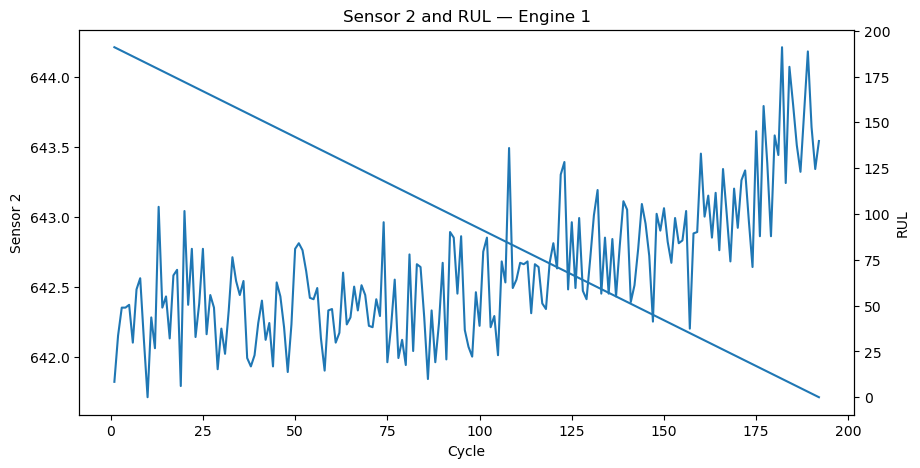

In [35]:
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(
    engine_1["cycle"],
    engine_1["sensor_2"]
)

ax1.set_xlabel("Cycle")
ax1.set_ylabel("Sensor 2")

ax2 = ax1.twinx()

ax2.plot(
    engine_1["cycle"],
    engine_1["RUL"]
)

ax2.set_ylabel("RUL")

plt.title("Sensor 2 and RUL — Engine 1")

plt.show()

In [36]:
train_df[sensor_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
sensor_1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100
sensor_7,20631.0,553.367711,8.850923e-01,549.8500,552.8100,553.4400,554.0100,556.0600
sensor_8,20631.0,2388.096652,7.098548e-02,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600
sensor_9,20631.0,9065.242941,2.208288e+01,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900
sensor_10,20631.0,1.300000,4.660829e-13,1.3000,1.3000,1.3000,1.3000,1.3000


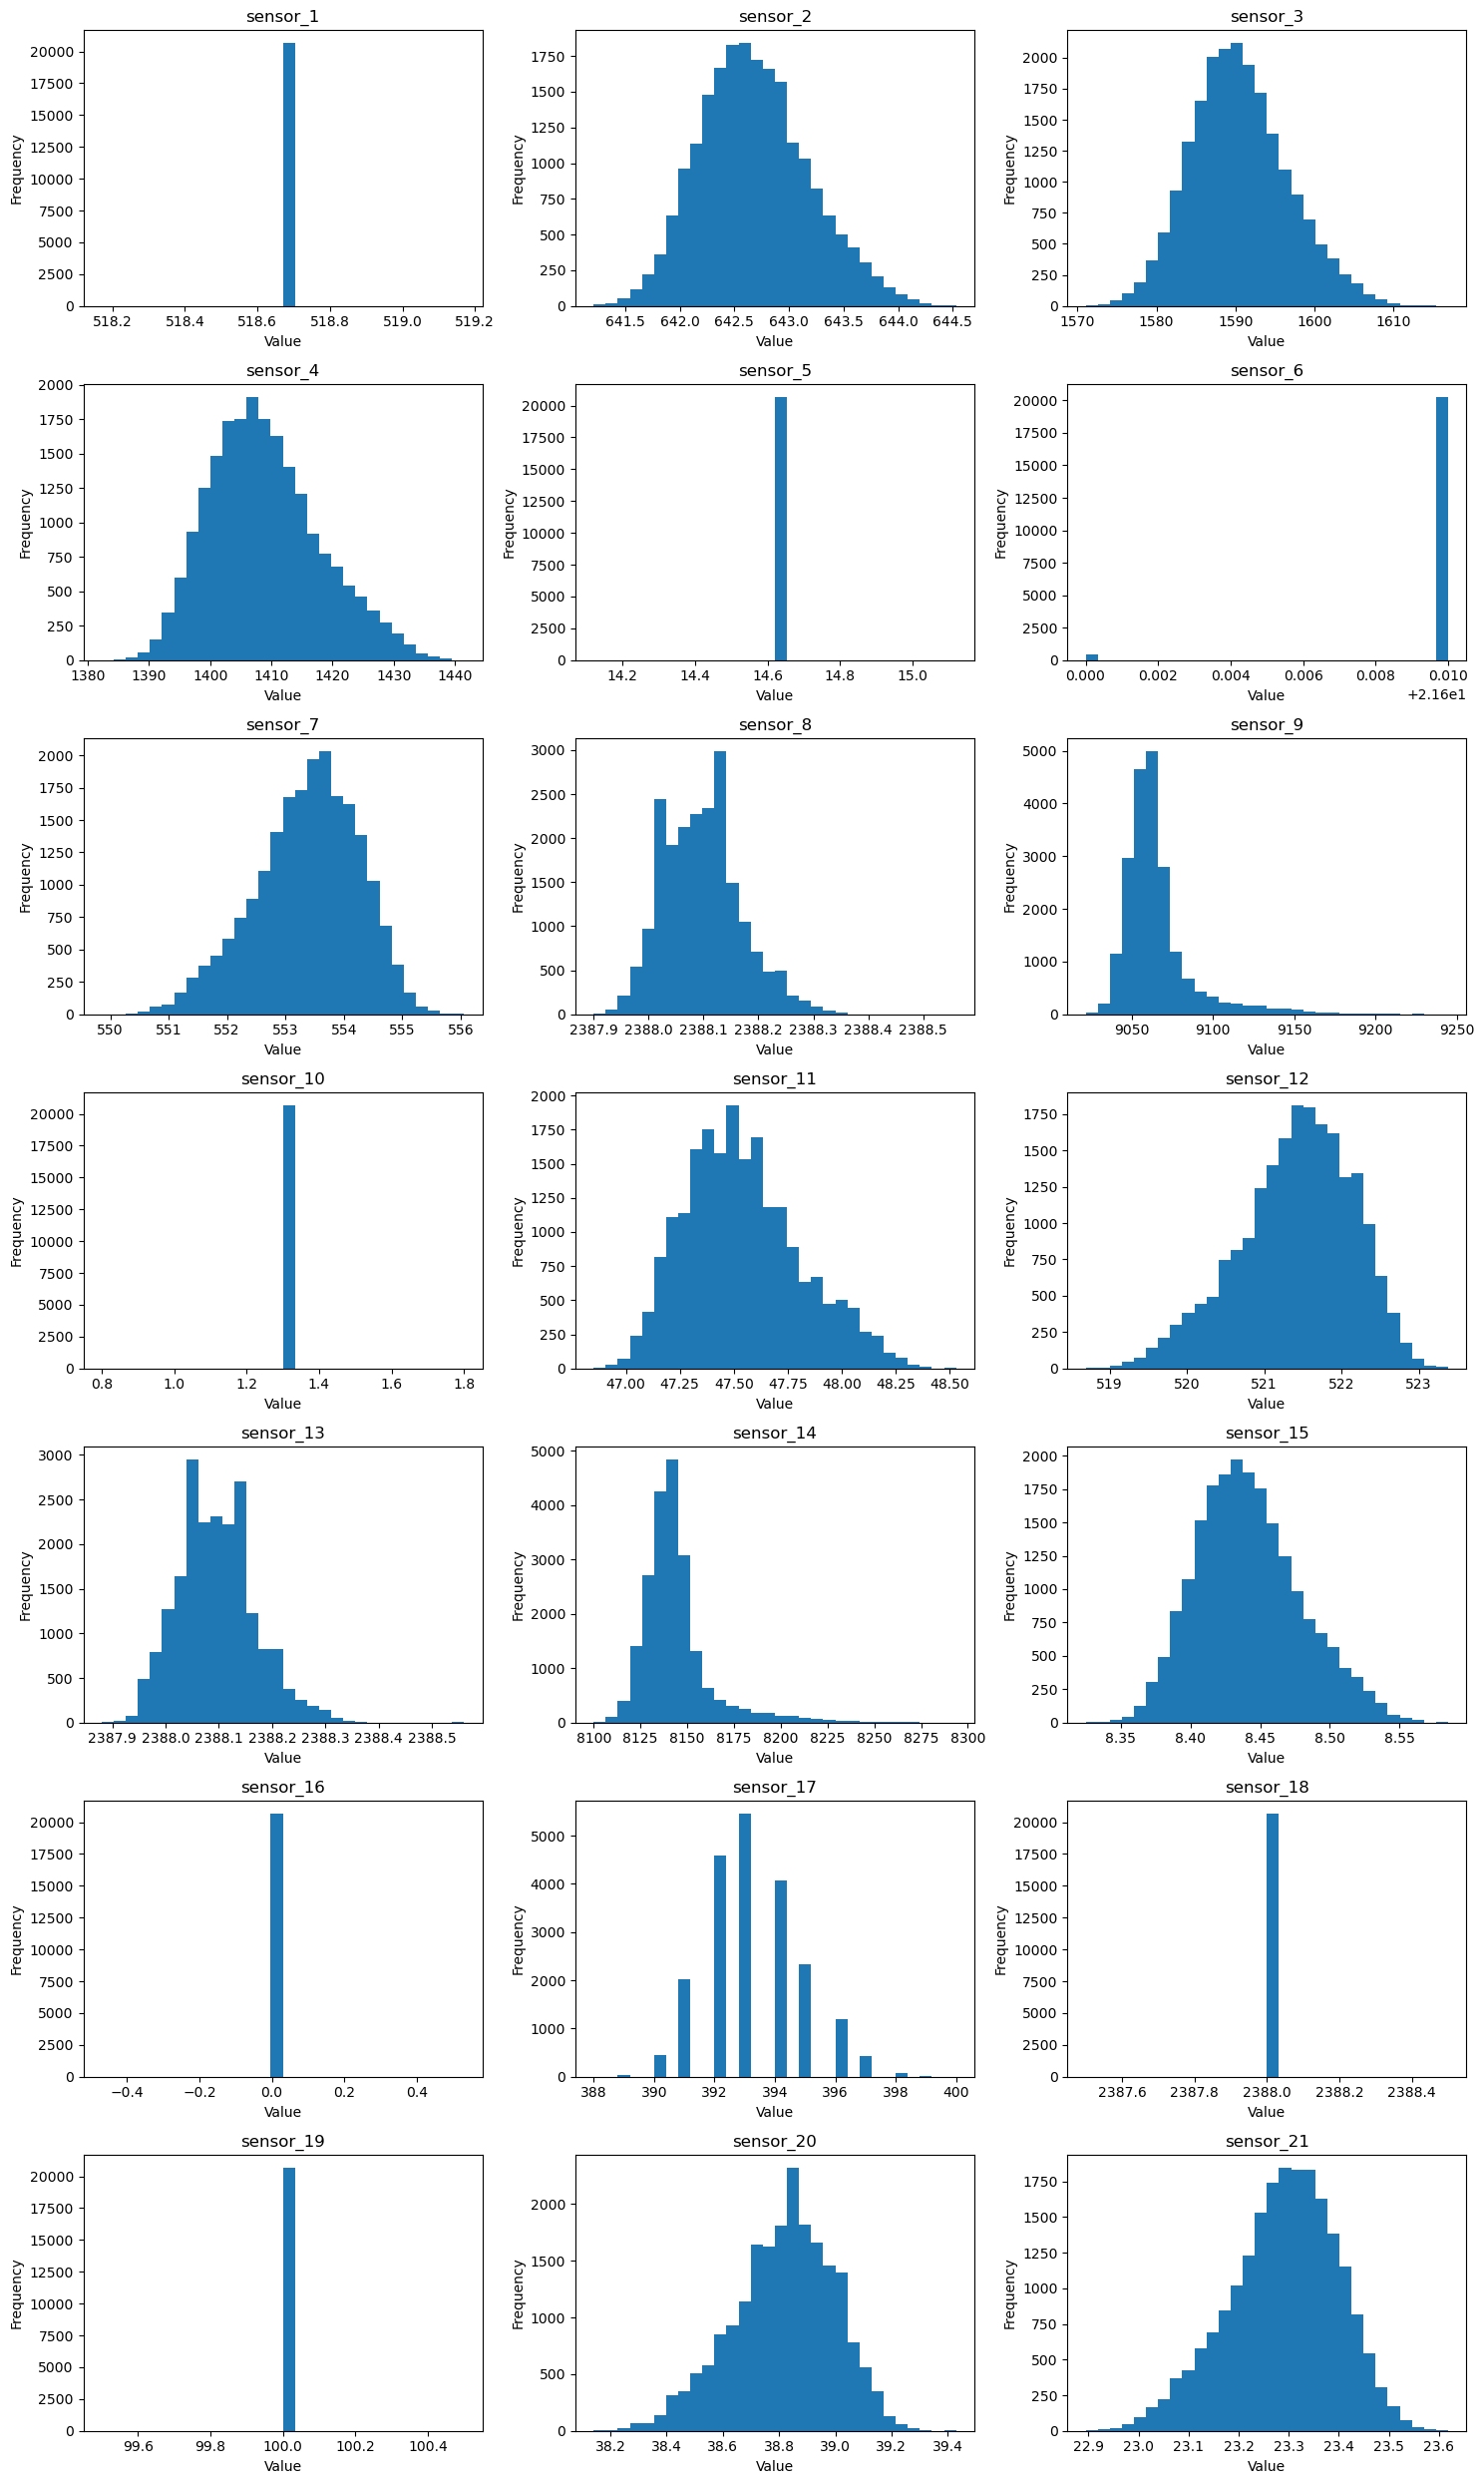

In [37]:
fig, axes = plt.subplots(7, 3, figsize=(15, 25))

for ax, sensor in zip(axes.flat, sensor_cols):
    ax.hist(train_df[sensor], bins=30)
    ax.set_title(sensor)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [38]:
setting_cols = [
    "setting_1",
    "setting_2",
    "setting_3"
]

In [39]:
train_df[setting_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
setting_1,20631.0,-0.000009,0.002187,-0.0087,-0.0015,0.0,0.0015,0.0087
setting_2,20631.0,0.000002,0.000293,-0.0006,-0.0002,0.0,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000,100.0000,100.0000,100.0,100.0000,100.0000


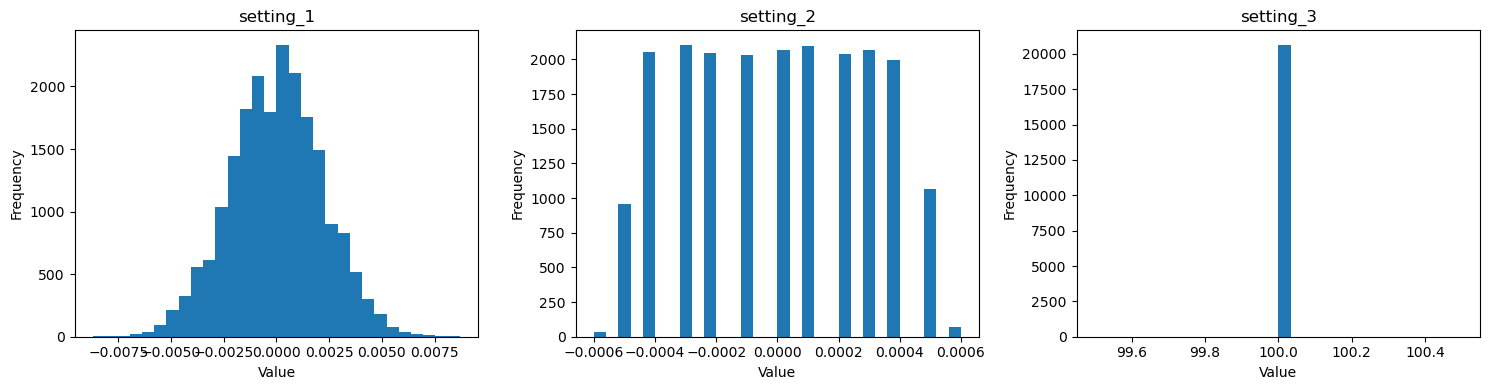

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, setting in zip(axes, setting_cols):
    ax.hist(train_df[setting], bins=30)
    ax.set_title(setting)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [41]:
corr = train_df[sensor_cols + ["RUL"]].corr()

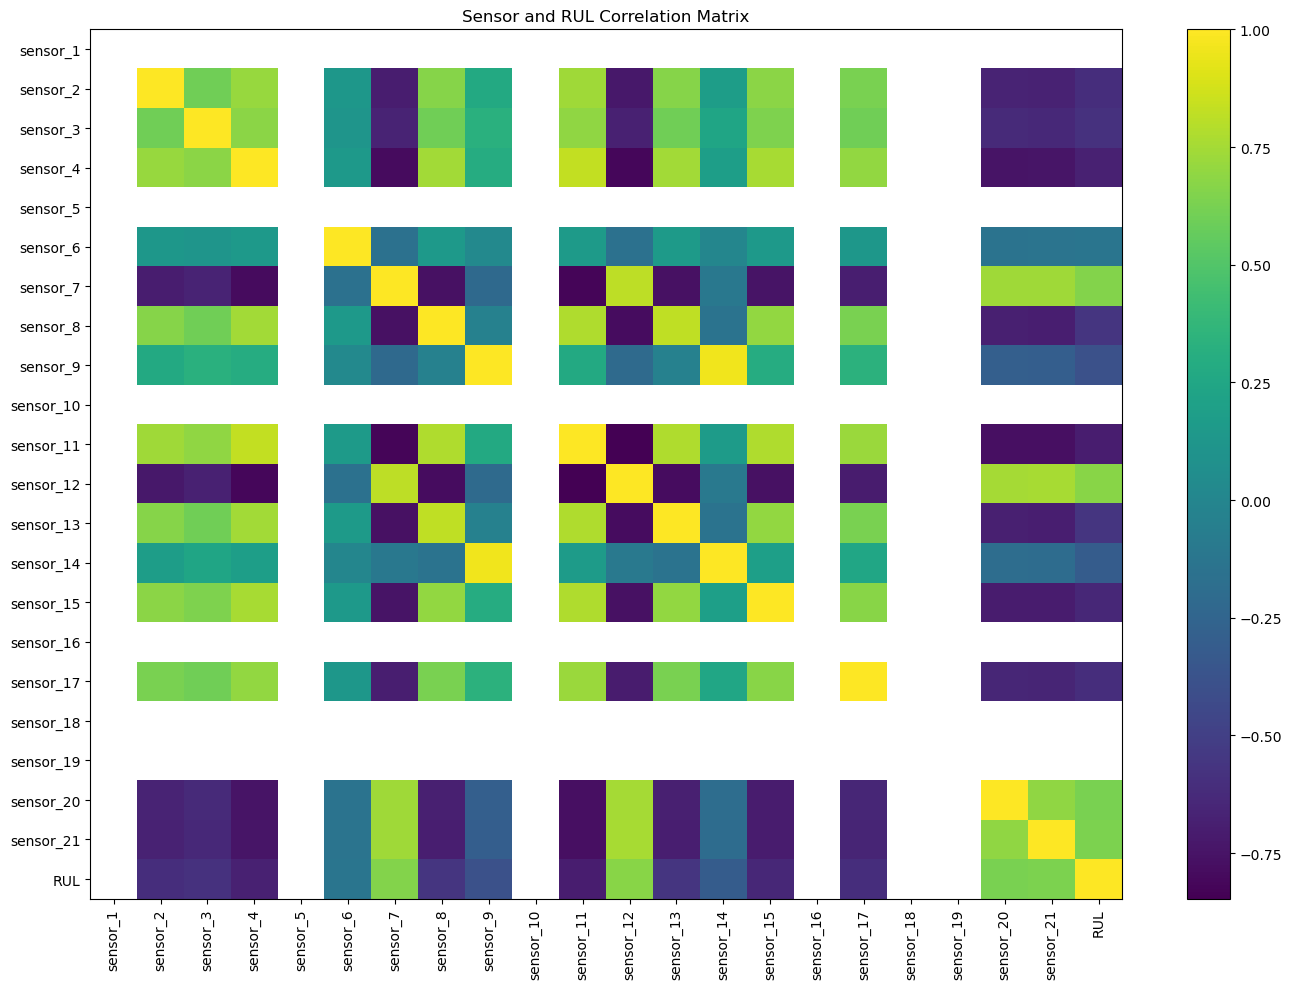

In [42]:
plt.figure(figsize=(14, 10))

plt.imshow(corr, aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Sensor and RUL Correlation Matrix")

plt.tight_layout()
plt.show()

In [43]:
feature_cols = [
    "setting_1",
    "setting_2",
    "setting_3"
] + sensor_cols

len(feature_cols), feature_cols

(24,
 ['setting_1',
  'setting_2',
  'setting_3',
  'sensor_1',
  'sensor_2',
  'sensor_3',
  'sensor_4',
  'sensor_5',
  'sensor_6',
  'sensor_7',
  'sensor_8',
  'sensor_9',
  'sensor_10',
  'sensor_11',
  'sensor_12',
  'sensor_13',
  'sensor_14',
  'sensor_15',
  'sensor_16',
  'sensor_17',
  'sensor_18',
  'sensor_19',
  'sensor_20',
  'sensor_21'])

In [44]:
feature_std = train_df[feature_cols].std()

feature_std.sort_values()

setting_3    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.556432e-14
sensor_10    4.660829e-13
sensor_5     3.394700e-12
sensor_1     6.537152e-11
setting_2    2.930621e-04
sensor_6     1.388985e-03
setting_1    2.187313e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64

In [45]:
feature_unique = train_df[feature_cols].nunique()

feature_unique.sort_values()

sensor_18       1
setting_3       1
sensor_1        1
sensor_16       1
sensor_19       1
sensor_10       1
sensor_5        1
sensor_6        2
setting_2      13
sensor_17      13
sensor_8       53
sensor_13      56
sensor_20     120
setting_1     158
sensor_11     159
sensor_2      310
sensor_12     427
sensor_7      513
sensor_15    1918
sensor_3     3012
sensor_4     4051
sensor_21    4745
sensor_14    6078
sensor_9     6403
dtype: int64

In [46]:
rul_corr = (
    train_df[feature_cols + ["RUL"]]
    .corr()["RUL"]
    .drop("RUL")
    .sort_values()
)

rul_corr

sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
setting_1   -0.003198
setting_2   -0.001948
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
setting_3         NaN
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64

In [47]:
feature_corr = train_df[feature_cols].corr()

feature_corr

,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
setting_1,1.000000,0.011660,NaN,NaN,0.009030,-0.005651,0.009544,NaN,-0.001340,-0.009437,...,-0.001491,0.002318,-0.004469,0.007652,NaN,0.002599,NaN,NaN,-0.005713,-0.014559
setting_2,0.011660,1.000000,NaN,NaN,0.007266,0.009068,0.014673,NaN,0.014355,-0.016678,...,-0.010923,0.018156,-0.006310,0.014156,NaN,0.012280,NaN,NaN,-0.010554,-0.007846
setting_3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sensor_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sensor_2,0.009030,0.007266,NaN,NaN,1.000000,0.602610,0.714949,NaN,0.132242,-0.702136,...,-0.724578,0.661792,0.179752,0.675975,NaN,0.629886,NaN,NaN,-0.661841,-0.668050
sensor_3,-0.005651,0.009068,NaN,NaN,0.602610,1.000000,0.678413,NaN,0.116039,-0.664595,...,-0.680307,0.600963,0.237137,0.639921,NaN,0.600017,NaN,NaN,-0.625941,-0.633901
sensor_4,0.009544,0.014673,NaN,NaN,0.714949,0.678413,1.000000,NaN,0.150480,-0.793130,...,-0.815591,0.745158,0.190748,0.758459,NaN,0.703499,NaN,NaN,-0.748067,-0.745193
sensor_5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sensor_6,-0.001340,0.014355,NaN,NaN,0.132242,0.116039,0.150480,NaN,1.000000,-0.155720,...,-0.155884,0.158276,-0.002112,0.149042,NaN,0.130810,NaN,NaN,-0.141419,-0.137419
sensor_7,-0.009437,-0.016678,NaN,NaN,-0.702136,-0.664595,-0.793130,NaN,-0.155720,1.000000,...,0.812713,-0.764611,-0.110053,-0.747051,NaN,-0.692893,NaN,NaN,0.736163,0.737447


In [48]:
import numpy as np

upper = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper.stack()
    .reset_index()
)

high_corr_pairs.columns = ["feature_1", "feature_2", "correlation"]

high_corr_pairs[
    high_corr_pairs["correlation"].abs() > 0.90
].sort_values(
    "correlation",
    key=abs,
    ascending=False
)

,feature_1,feature_2,correlation
280,sensor_9,sensor_14,0.963157


In [49]:
engine_ids = train_df["unit"].unique()

engine_ids

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100], dtype=int64)

In [50]:
from sklearn.model_selection import train_test_split

train_engines, val_engines = train_test_split(
    engine_ids,
    test_size=0.20,
    random_state=42
)

In [51]:
print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))

Training engines: 80
Validation engines: 20


In [52]:
print("Common engines:",
      set(train_engines).intersection(set(val_engines)))

Common engines: set()


In [53]:
train_data = train_df[
    train_df["unit"].isin(train_engines)
].copy()

val_data = train_df[
    train_df["unit"].isin(val_engines)
].copy()

In [54]:
print("Training rows:", train_data.shape)
print("Validation rows:", val_data.shape)

Training rows: (16561, 27)
Validation rows: (4070, 27)


In [55]:
X_train = train_data[feature_cols]
y_train = train_data["RUL"]

X_val = val_data[feature_cols]
y_val = val_data["RUL"]

In [56]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (16561, 24)
y_train: (16561,)
X_val: (4070, 24)
y_val: (4070,)


In [57]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

In [58]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(
    X_train_scaled,
    y_train
)

LinearRegression()

In [59]:
y_pred = lr_model.predict(X_val_scaled)

In [60]:
print(y_pred[:10])
print(y_val.iloc[:10].values)

[156.73419688 152.55362701 164.16243147 180.75813398 153.38734676
 173.91296434 163.52997676 170.27464306 170.71889603 168.36966847]
[191 190 189 188 187 186 185 184 183 182]


In [61]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_val, y_pred)

print("MAE:", mae)

MAE: 30.111252539998226


In [62]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(
    mean_squared_error(y_val, y_pred)
)

print("RMSE:", rmse)

RMSE: 38.132534801274744


In [63]:
print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual values:")
print(y_val.iloc[:10].values)

First 10 predictions:
[156.73419688 152.55362701 164.16243147 180.75813398 153.38734676
 173.91296434 163.52997676 170.27464306 170.71889603 168.36966847]

First 10 actual values:
[191 190 189 188 187 186 185 184 183 182]


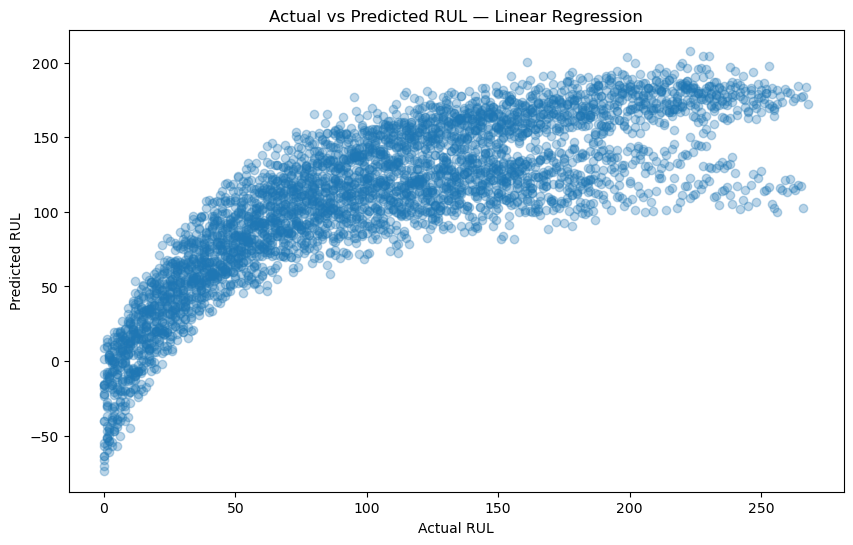

In [64]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_val,
    y_pred,
    alpha=0.3
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL — Linear Regression")

plt.show()

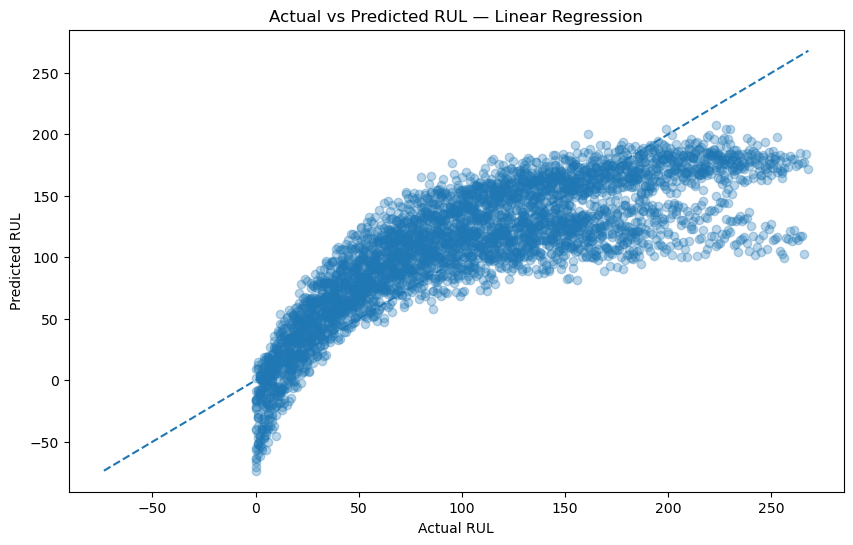

In [65]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_val,
    y_pred,
    alpha=0.3
)

min_val = min(y_val.min(), y_pred.min())
max_val = max(y_val.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL — Linear Regression")

plt.show()

In [66]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [67]:
rf_model.fit(
    X_train,
    y_train
)

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

In [68]:
rf_pred = rf_model.predict(X_val)

In [69]:
rf_mae = mean_absolute_error(
    y_val,
    rf_pred
)

print("Random Forest MAE:", rf_mae)

Random Forest MAE: 25.873658476658477


In [70]:
rf_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        rf_pred
    )
)

print("Random Forest RMSE:", rf_rmse)

Random Forest RMSE: 35.40895893849618


In [71]:
print("Model Performance")
print("-------------------------")

print("Linear Regression")
print("MAE :", mae)
print("RMSE:", rmse)

print()

print("Random Forest")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)

Model Performance
-------------------------
Linear Regression
MAE : 30.111252539998226
RMSE: 38.132534801274744

Random Forest
MAE : 25.873658476658477
RMSE: 35.40895893849618


In [72]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

feature_importance

sensor_11    0.433487
sensor_9     0.125889
sensor_4     0.077079
sensor_12    0.045263
sensor_14    0.040649
sensor_7     0.037675
sensor_15    0.033759
sensor_21    0.032362
sensor_3     0.029497
sensor_2     0.028251
sensor_20    0.024712
setting_1    0.024187
sensor_8     0.021023
sensor_13    0.020924
setting_2    0.014715
sensor_17    0.009832
sensor_6     0.000698
sensor_5     0.000000
sensor_1     0.000000
sensor_16    0.000000
sensor_18    0.000000
sensor_19    0.000000
setting_3    0.000000
sensor_10    0.000000
dtype: float64

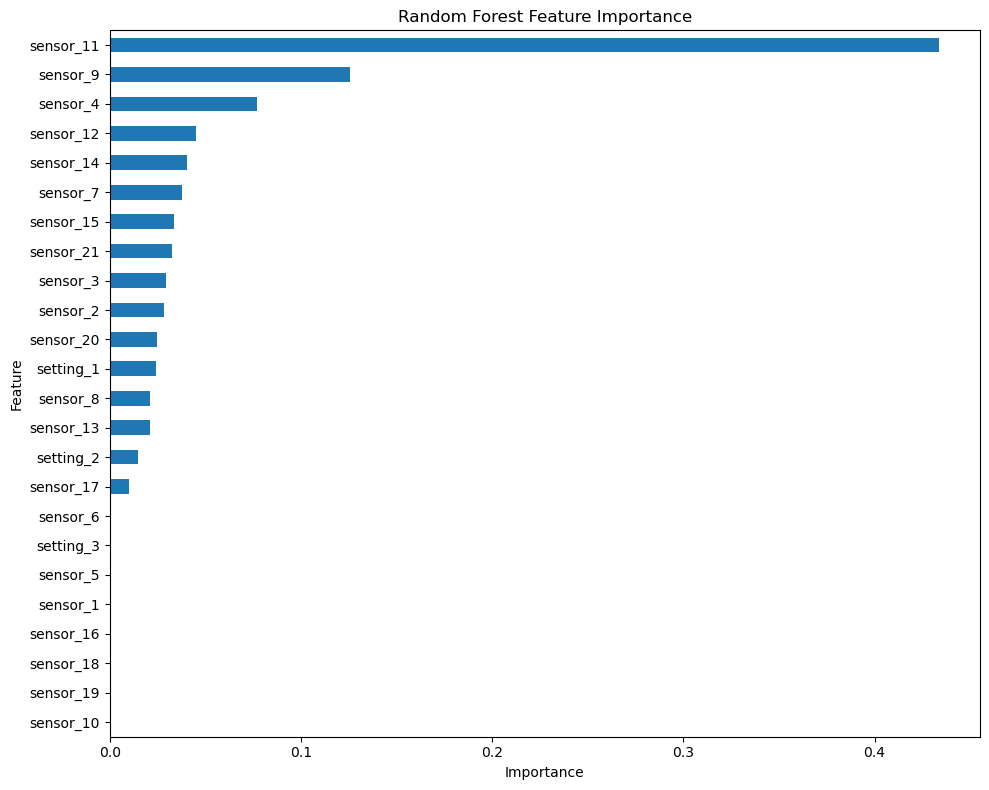

In [73]:
plt.figure(figsize=(10, 8))

feature_importance.sort_values().plot(
    kind="barh"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

In [74]:
train_df["sensor_2_roll5"] = (
    train_df
    .groupby("unit")["sensor_2"]
    .transform(
        lambda x: x.rolling(window=5, min_periods=1).mean()
    )
)

In [75]:
train_df[
    train_df["unit"] == 1
][
    ["unit", "cycle", "sensor_2", "sensor_2_roll5"]
].head(15)

,unit,cycle,sensor_2,sensor_2_roll5
0,1,1,641.82,641.820000
1,1,2,642.15,641.985000
2,1,3,642.35,642.106667
3,1,4,642.35,642.167500
4,1,5,642.37,642.208000
5,1,6,642.10,642.264000
6,1,7,642.48,642.330000
7,1,8,642.56,642.372000
8,1,9,642.12,642.326000
9,1,10,641.71,642.194000


In [76]:
train_df["sensor_2_roll_std5"] = (
    train_df
    .groupby("unit")["sensor_2"]
    .transform(
        lambda x: x.rolling(window=5, min_periods=1).std()
    )
)

In [77]:
train_df[
    train_df["unit"] == 1
][
    ["cycle", "sensor_2", "sensor_2_roll5", "sensor_2_roll_std5"]
].head(15)

,cycle,sensor_2,sensor_2_roll5,sensor_2_roll_std5
0,1,641.82,641.820000,NaN
1,2,642.15,641.985000,0.233345
2,3,642.35,642.106667,0.267644
3,4,642.35,642.167500,0.250117
4,5,642.37,642.208000,0.234776
5,6,642.10,642.264000,0.128374
6,7,642.48,642.330000,0.139463
7,8,642.56,642.372000,0.174270
8,9,642.12,642.326000,0.208519
9,10,641.71,642.194000,0.340705


In [78]:
train_df["sensor_2_change"] = (
    train_df
    .groupby("unit")["sensor_2"]
    .diff()
)

In [79]:
train_df[
    train_df["unit"] == 1
][
    ["cycle", "sensor_2", "sensor_2_change"]
].head(15)

,cycle,sensor_2,sensor_2_change
0,1,641.82,NaN
1,2,642.15,0.33
2,3,642.35,0.20
3,4,642.35,0.00
4,5,642.37,0.02
5,6,642.10,-0.27
6,7,642.48,0.38
7,8,642.56,0.08
8,9,642.12,-0.44
9,10,641.71,-0.41


In [80]:
train_df["sensor_2_roll_mean_5"] = (
    train_df
    .groupby("unit")["sensor_2"]
    .transform(
        lambda x: x.rolling(
            window=5,
            min_periods=1
        ).mean()
    )
)

In [81]:
train_df[
    train_df["unit"] == 1
][
    [
        "cycle",
        "sensor_2",
        "sensor_2_change",
        "sensor_2_roll_mean_5"
    ]
].head(15)

,cycle,sensor_2,sensor_2_change,sensor_2_roll_mean_5
0,1,641.82,NaN,641.820000
1,2,642.15,0.33,641.985000
2,3,642.35,0.20,642.106667
3,4,642.35,0.00,642.167500
4,5,642.37,0.02,642.208000
5,6,642.10,-0.27,642.264000
6,7,642.48,0.38,642.330000
7,8,642.56,0.08,642.372000
8,9,642.12,-0.44,642.326000
9,10,641.71,-0.41,642.194000


In [82]:
train_df["sensor_2_roll_std_5"] = (
    train_df
    .groupby("unit")["sensor_2"]
    .transform(
        lambda x: x.rolling(
            window=5,
            min_periods=1
        ).std()
    )
)

In [83]:
train_df[
    train_df["unit"] == 1
][
    [
        "cycle",
        "sensor_2",
        "sensor_2_change",
        "sensor_2_roll_mean_5",
        "sensor_2_roll_std_5"
    ]
].head(15)

,cycle,sensor_2,sensor_2_change,sensor_2_roll_mean_5,sensor_2_roll_std_5
0,1,641.82,NaN,641.820000,NaN
1,2,642.15,0.33,641.985000,0.233345
2,3,642.35,0.20,642.106667,0.267644
3,4,642.35,0.00,642.167500,0.250117
4,5,642.37,0.02,642.208000,0.234776
5,6,642.10,-0.27,642.264000,0.128374
6,7,642.48,0.38,642.330000,0.139463
7,8,642.56,0.08,642.372000,0.174270
8,9,642.12,-0.44,642.326000,0.208519
9,10,641.71,-0.41,642.194000,0.340705


In [84]:
train_df["sensor_2_roll_mean_10"] = (
    train_df
    .groupby("unit")["sensor_2"]
    .transform(
        lambda x: x.rolling(
            window=10,
            min_periods=1
        ).mean()
    )
)

In [85]:
train_df[
    train_df["unit"] == 1
][
    [
        "cycle",
        "sensor_2",
        "sensor_2_change",
        "sensor_2_roll_mean_5",
        "sensor_2_roll_mean_10",
        "sensor_2_roll_std_5"
    ]
].head(15)

,cycle,sensor_2,sensor_2_change,sensor_2_roll_mean_5,sensor_2_roll_mean_10,sensor_2_roll_std_5
0,1,641.82,NaN,641.820000,641.820000,NaN
1,2,642.15,0.33,641.985000,641.985000,0.233345
2,3,642.35,0.20,642.106667,642.106667,0.267644
3,4,642.35,0.00,642.167500,642.167500,0.250117
4,5,642.37,0.02,642.208000,642.208000,0.234776
5,6,642.10,-0.27,642.264000,642.190000,0.128374
6,7,642.48,0.38,642.330000,642.231429,0.139463
7,8,642.56,0.08,642.372000,642.272500,0.174270
8,9,642.12,-0.44,642.326000,642.255556,0.208519
9,10,641.71,-0.41,642.194000,642.201000,0.340705


In [86]:
feature_importance.head(10)

sensor_11    0.433487
sensor_9     0.125889
sensor_4     0.077079
sensor_12    0.045263
sensor_14    0.040649
sensor_7     0.037675
sensor_15    0.033759
sensor_21    0.032362
sensor_3     0.029497
sensor_2     0.028251
dtype: float64

In [87]:
selected_sensors = [
    "sensor_11",
    "sensor_9",
    "sensor_4",
    "sensor_12",
    "sensor_14",
    "sensor_7",
    "sensor_15",
    "sensor_21",
    "sensor_3",
    "sensor_2"
]

In [88]:
for sensor in selected_sensors:
    train_df[f"{sensor}_change"] = (
        train_df
        .groupby("unit")[sensor]
        .diff()
    )

In [89]:
change_features = [
    f"{sensor}_change"
    for sensor in selected_sensors
]

print(change_features)

['sensor_11_change', 'sensor_9_change', 'sensor_4_change', 'sensor_12_change', 'sensor_14_change', 'sensor_7_change', 'sensor_15_change', 'sensor_21_change', 'sensor_3_change', 'sensor_2_change']


In [90]:
train_df[
    train_df["unit"] == 1
][
    ["cycle", "sensor_11", "sensor_11_change",
     "sensor_9", "sensor_9_change"]
].head(10)

,cycle,sensor_11,sensor_11_change,sensor_9,sensor_9_change
0,1,47.47,NaN,9046.19,NaN
1,2,47.49,0.02,9044.07,-2.12
2,3,47.27,-0.22,9052.94,8.87
3,4,47.13,-0.14,9049.48,-3.46
4,5,47.28,0.15,9055.15,5.67
5,6,47.16,-0.12,9049.68,-5.47
6,7,47.36,0.20,9059.13,9.45
7,8,47.24,-0.12,9040.80,-18.33
8,9,47.29,0.05,9046.46,5.66
9,10,47.03,-0.26,9051.70,5.24


In [91]:
for sensor in selected_sensors:
    train_df[f"{sensor}_roll_mean_5"] = (
        train_df
        .groupby("unit")[sensor]
        .transform(
            lambda x: x.rolling(
                window=5,
                min_periods=1
            ).mean()
        )
    )

In [92]:
train_df[
    train_df["unit"] == 1
][
    [
        "cycle",
        "sensor_11",
        "sensor_11_roll_mean_5"
    ]
].head(10)

,cycle,sensor_11,sensor_11_roll_mean_5
0,1,47.47,47.470
1,2,47.49,47.480
2,3,47.27,47.410
3,4,47.13,47.340
4,5,47.28,47.328
5,6,47.16,47.266
6,7,47.36,47.240
7,8,47.24,47.234
8,9,47.29,47.266
9,10,47.03,47.216


In [93]:
for sensor in selected_sensors:
    train_df[f"{sensor}_roll_std_5"] = (
        train_df
        .groupby("unit")[sensor]
        .transform(
            lambda x: x.rolling(
                window=5,
                min_periods=1
            ).std()
        )
    )

In [94]:
for sensor in selected_sensors:
    train_df[f"{sensor}_roll_mean_10"] = (
        train_df
        .groupby("unit")[sensor]
        .transform(
            lambda x: x.rolling(
                window=10,
                min_periods=1
            ).mean()
        )
    )

In [95]:
train_df[
    train_df["unit"] == 1
][
    [
        "cycle",
        "sensor_11",
        "sensor_11_roll_mean_5",
        "sensor_11_roll_mean_10"
    ]
].head(15)

,cycle,sensor_11,sensor_11_roll_mean_5,sensor_11_roll_mean_10
0,1,47.47,47.470,47.470000
1,2,47.49,47.480,47.480000
2,3,47.27,47.410,47.410000
3,4,47.13,47.340,47.340000
4,5,47.28,47.328,47.328000
5,6,47.16,47.266,47.300000
6,7,47.36,47.240,47.308571
7,8,47.24,47.234,47.300000
8,9,47.29,47.266,47.298889
9,10,47.03,47.216,47.272000


In [96]:
engineered_features = [
    col for col in train_df.columns
    if (
        "_change" in col
        or "_roll_mean_5" in col
        or "_roll_std_5" in col
        or "_roll_mean_10" in col
    )
]

print("Number of engineered features:", len(engineered_features))
print(engineered_features)

Number of engineered features: 40
['sensor_2_change', 'sensor_2_roll_mean_5', 'sensor_2_roll_std_5', 'sensor_2_roll_mean_10', 'sensor_11_change', 'sensor_9_change', 'sensor_4_change', 'sensor_12_change', 'sensor_14_change', 'sensor_7_change', 'sensor_15_change', 'sensor_21_change', 'sensor_3_change', 'sensor_11_roll_mean_5', 'sensor_9_roll_mean_5', 'sensor_4_roll_mean_5', 'sensor_12_roll_mean_5', 'sensor_14_roll_mean_5', 'sensor_7_roll_mean_5', 'sensor_15_roll_mean_5', 'sensor_21_roll_mean_5', 'sensor_3_roll_mean_5', 'sensor_11_roll_std_5', 'sensor_9_roll_std_5', 'sensor_4_roll_std_5', 'sensor_12_roll_std_5', 'sensor_14_roll_std_5', 'sensor_7_roll_std_5', 'sensor_15_roll_std_5', 'sensor_21_roll_std_5', 'sensor_3_roll_std_5', 'sensor_11_roll_mean_10', 'sensor_9_roll_mean_10', 'sensor_4_roll_mean_10', 'sensor_12_roll_mean_10', 'sensor_14_roll_mean_10', 'sensor_7_roll_mean_10', 'sensor_15_roll_mean_10', 'sensor_21_roll_mean_10', 'sensor_3_roll_mean_10']


In [97]:
engineered_feature_cols = (
    feature_cols +
    engineered_features
)

print("Total features:", len(engineered_feature_cols))
print(engineered_feature_cols)

Total features: 64
['setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'sensor_2_change', 'sensor_2_roll_mean_5', 'sensor_2_roll_std_5', 'sensor_2_roll_mean_10', 'sensor_11_change', 'sensor_9_change', 'sensor_4_change', 'sensor_12_change', 'sensor_14_change', 'sensor_7_change', 'sensor_15_change', 'sensor_21_change', 'sensor_3_change', 'sensor_11_roll_mean_5', 'sensor_9_roll_mean_5', 'sensor_4_roll_mean_5', 'sensor_12_roll_mean_5', 'sensor_14_roll_mean_5', 'sensor_7_roll_mean_5', 'sensor_15_roll_mean_5', 'sensor_21_roll_mean_5', 'sensor_3_roll_mean_5', 'sensor_11_roll_std_5', 'sensor_9_roll_std_5', 'sensor_4_roll_std_5', 'sensor_12_roll_std_5', 'sensor_14_roll_std_5', 'sensor_7_roll_std_5', 'sensor_15_roll_std_5', 'sensor_21_roll_std_5', 

In [98]:
train_df[engineered_feature_cols].isnull().sum().sort_values(ascending=False).head(20)

sensor_14_change        100
sensor_14_roll_std_5    100
sensor_21_change        100
sensor_15_change        100
sensor_7_change         100
sensor_12_change        100
sensor_4_change         100
sensor_9_change         100
sensor_11_change        100
sensor_2_roll_std_5     100
sensor_2_change         100
sensor_9_roll_std_5     100
sensor_4_roll_std_5     100
sensor_12_roll_std_5    100
sensor_11_roll_std_5    100
sensor_7_roll_std_5     100
sensor_3_roll_std_5     100
sensor_15_roll_std_5    100
sensor_3_change         100
sensor_21_roll_std_5    100
dtype: int64

In [99]:
nan_counts = (
    train_df[engineered_feature_cols]
    .isnull()
    .sum()
)

nan_counts[nan_counts > 0]

sensor_2_change         100
sensor_2_roll_std_5     100
sensor_11_change        100
sensor_9_change         100
sensor_4_change         100
sensor_12_change        100
sensor_14_change        100
sensor_7_change         100
sensor_15_change        100
sensor_21_change        100
sensor_3_change         100
sensor_11_roll_std_5    100
sensor_9_roll_std_5     100
sensor_4_roll_std_5     100
sensor_12_roll_std_5    100
sensor_14_roll_std_5    100
sensor_7_roll_std_5     100
sensor_15_roll_std_5    100
sensor_21_roll_std_5    100
sensor_3_roll_std_5     100
dtype: int64

In [100]:
train_data = train_df[
    train_df["unit"].isin(train_engines)
].copy()

val_data = train_df[
    train_df["unit"].isin(val_engines)
].copy()

In [101]:
train_data = train_data.dropna(
    subset=engineered_feature_cols
)

val_data = val_data.dropna(
    subset=engineered_feature_cols
)

In [102]:
print("Train shape:", train_data.shape)
print("Validation shape:", val_data.shape)

print(
    "Train NaNs:",
    train_data[engineered_feature_cols].isnull().sum().sum()
)

print(
    "Validation NaNs:",
    val_data[engineered_feature_cols].isnull().sum().sum()
)

Train shape: (16481, 69)
Validation shape: (4050, 69)
Train NaNs: 0
Validation NaNs: 0


In [103]:
rf_fe_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_fe_model.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

In [104]:
rf_fe_pred = rf_fe_model.predict(X_val)

In [105]:
rf_fe_mae = mean_absolute_error(
    y_val,
    rf_fe_pred
)

rf_fe_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        rf_fe_pred
    )
)

print("Feature-Engineered RF MAE:", rf_fe_mae)
print("Feature-Engineered RF RMSE:", rf_fe_rmse)

Feature-Engineered RF MAE: 25.873658476658477
Feature-Engineered RF RMSE: 35.40895893849618


In [106]:
print("X_train features:", X_train.shape[1])
print("Model features:", rf_fe_model.n_features_in_)

X_train features: 24
Model features: 24


In [107]:
# Build training and validation features using all 64 features

X_train_fe = train_data[engineered_feature_cols]
y_train_fe = train_data["RUL"]

X_val_fe = val_data[engineered_feature_cols]
y_val_fe = val_data["RUL"]

print("X_train_fe:", X_train_fe.shape)
print("X_val_fe:", X_val_fe.shape)

X_train_fe: (16481, 64)
X_val_fe: (4050, 64)


In [109]:
rf_fe_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_fe_model.fit(X_train_fe, y_train_fe)

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

In [111]:
print("Model features:", rf_fe_model.n_features_in_)

Model features: 64


In [113]:
print("X_train_fe:", X_train_fe.shape)
print("X_val_fe:", X_val_fe.shape)
print("Model features:", rf_fe_model.n_features_in_)

X_train_fe: (16481, 64)
X_val_fe: (4050, 64)
Model features: 64


In [115]:
fe_importance = pd.Series(
    rf_fe_model.feature_importances_,
    index=engineered_feature_cols
).sort_values(ascending=False)

print(fe_importance.head(20))

sensor_4_roll_mean_10     0.251201
sensor_4_roll_mean_5      0.145431
sensor_9_roll_mean_10     0.077960
sensor_21_roll_mean_10    0.072261
sensor_15_roll_mean_10    0.056549
sensor_14_roll_mean_10    0.034904
sensor_11_roll_mean_5     0.034686
sensor_9_roll_mean_5      0.029075
sensor_2_roll_mean_10     0.027753
sensor_7_roll_mean_10     0.027449
sensor_3_roll_mean_10     0.025438
sensor_11_roll_mean_10    0.018692
sensor_12_roll_mean_10    0.016689
sensor_14_roll_mean_5     0.011532
sensor_21_roll_mean_5     0.009334
sensor_12_roll_mean_5     0.008280
sensor_7_roll_mean_5      0.008104
sensor_3_roll_std_5       0.007863
sensor_15_roll_std_5      0.007590
sensor_21_roll_std_5      0.007484
dtype: float64


In [117]:
print(fe_importance.head(20))

sensor_4_roll_mean_10     0.251201
sensor_4_roll_mean_5      0.145431
sensor_9_roll_mean_10     0.077960
sensor_21_roll_mean_10    0.072261
sensor_15_roll_mean_10    0.056549
sensor_14_roll_mean_10    0.034904
sensor_11_roll_mean_5     0.034686
sensor_9_roll_mean_5      0.029075
sensor_2_roll_mean_10     0.027753
sensor_7_roll_mean_10     0.027449
sensor_3_roll_mean_10     0.025438
sensor_11_roll_mean_10    0.018692
sensor_12_roll_mean_10    0.016689
sensor_14_roll_mean_5     0.011532
sensor_21_roll_mean_5     0.009334
sensor_12_roll_mean_5     0.008280
sensor_7_roll_mean_5      0.008104
sensor_3_roll_std_5       0.007863
sensor_15_roll_std_5      0.007590
sensor_21_roll_std_5      0.007484
dtype: float64


In [119]:
print(fe_importance.head(20).index.tolist())

['sensor_4_roll_mean_10', 'sensor_4_roll_mean_5', 'sensor_9_roll_mean_10', 'sensor_21_roll_mean_10', 'sensor_15_roll_mean_10', 'sensor_14_roll_mean_10', 'sensor_11_roll_mean_5', 'sensor_9_roll_mean_5', 'sensor_2_roll_mean_10', 'sensor_7_roll_mean_10', 'sensor_3_roll_mean_10', 'sensor_11_roll_mean_10', 'sensor_12_roll_mean_10', 'sensor_14_roll_mean_5', 'sensor_21_roll_mean_5', 'sensor_12_roll_mean_5', 'sensor_7_roll_mean_5', 'sensor_3_roll_std_5', 'sensor_15_roll_std_5', 'sensor_21_roll_std_5']


In [121]:
selected_engineered_features = fe_importance.head(20).index.tolist()

print("Selected features:", len(selected_engineered_features))
print(selected_engineered_features)

Selected features: 20
['sensor_4_roll_mean_10', 'sensor_4_roll_mean_5', 'sensor_9_roll_mean_10', 'sensor_21_roll_mean_10', 'sensor_15_roll_mean_10', 'sensor_14_roll_mean_10', 'sensor_11_roll_mean_5', 'sensor_9_roll_mean_5', 'sensor_2_roll_mean_10', 'sensor_7_roll_mean_10', 'sensor_3_roll_mean_10', 'sensor_11_roll_mean_10', 'sensor_12_roll_mean_10', 'sensor_14_roll_mean_5', 'sensor_21_roll_mean_5', 'sensor_12_roll_mean_5', 'sensor_7_roll_mean_5', 'sensor_3_roll_std_5', 'sensor_15_roll_std_5', 'sensor_21_roll_std_5']


In [123]:
X_train_selected = train_data[selected_engineered_features]
X_val_selected = val_data[selected_engineered_features]

y_train_selected = train_data["RUL"]
y_val_selected = val_data["RUL"]

In [125]:
rf_selected = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_selected.fit(
    X_train_selected,
    y_train_selected
)

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

In [127]:
selected_pred = rf_selected.predict(X_val_selected)

In [129]:
selected_mae = mean_absolute_error(
    y_val_selected,
    selected_pred
)

selected_rmse = np.sqrt(
    mean_squared_error(
        y_val_selected,
        selected_pred
    )
)

print("Selected-feature RF MAE:", selected_mae)
print("Selected-feature RF RMSE:", selected_rmse)

Selected-feature RF MAE: 24.45104197530864
Selected-feature RF RMSE: 34.98957561515137


In [131]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=42
)

gb_model.fit(
    X_train_selected,
    y_train_selected
)

gb_pred = gb_model.predict(X_val_selected)

gb_mae = mean_absolute_error(
    y_val_selected,
    gb_pred
)

gb_rmse = np.sqrt(
    mean_squared_error(
        y_val_selected,
        gb_pred
    )
)

print("Gradient Boosting MAE:", gb_mae)
print("Gradient Boosting RMSE:", gb_rmse)

Gradient Boosting MAE: 24.37320109602114
Gradient Boosting RMSE: 33.857072446958114


In [132]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_selected,
    y_train_selected
)

xgb_pred = xgb_model.predict(X_val_selected)

xgb_mae = mean_absolute_error(
    y_val_selected,
    xgb_pred
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_val_selected,
        xgb_pred
    )
)

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)

XGBoost MAE: 24.549298438025108
XGBoost RMSE: 34.516381244736664


In [133]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor

xgb_base = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [200, 300, 500, 700],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [3, 4, 5, 6],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "reg_alpha": [0, 0.01, 0.1],
    "reg_lambda": [1, 2, 5]
}

In [137]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(
    X_train_selected,
    y_train_selected
)

Fitting 3 folds for each of 30 candidates, totalling 90 fits


RandomizedSearchCV(cv=3,
                   estimator=XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=None, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=True,
                                          eval_metric=None, feature_types=None,
                                          feature_weights=None, gamma=None,
                                          grow_policy=None,
                                          importance_type=None,
                                          interaction_constraints...
                                          num_parallel_tree=None, ...),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 0.9,
                                                             1.0],
                                        'learning_rate': [0.01, 0.03, 0.05,
                                                          0.1],
                                        'max_depth': [3, 4, 5, 6],
                                        'min_child_weight': [1, 3, 5],
                                        'n_estimators': [200, 300, 500, 700],
                                        'reg_alpha': [0, 0.01, 0.1],
                                        'reg_lambda': [1, 2, 5],
                                        'subsample': [0.7, 0.8, 0.9, 1.0]},
                   random_state=42, scoring='neg_mean_absolute_error',
                   verbose=1)

In [138]:
print("Best parameters:")
print(xgb_search.best_params_)

print("\nBest CV MAE:")
print(-xgb_search.best_score_)

Best parameters:
{'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha': 0.1, 'n_estimators': 700, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.7}

Best CV MAE:
31.726446191735846


In [141]:
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

group_kfold = GroupKFold(n_splits=3)

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=group_kfold,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(
    X_train_selected,
    y_train_selected,
    groups=train_data["unit"]
)

Fitting 3 folds for each of 30 candidates, totalling 90 fits


RandomizedSearchCV(cv=GroupKFold(n_splits=3),
                   estimator=XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=None, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=True,
                                          eval_metric=None, feature_types=None,
                                          feature_weights=None, gamma=None,
                                          grow_policy=None,
                                          importance_type=None,
                                          in...
                                          num_parallel_tree=None, ...),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 0.9,
                                                             1.0],
                                        'learning_rate': [0.01, 0.03, 0.05,
                                                          0.1],
                                        'max_depth': [3, 4, 5, 6],
                                        'min_child_weight': [1, 3, 5],
                                        'n_estimators': [200, 300, 500, 700],
                                        'reg_alpha': [0, 0.01, 0.1],
                                        'reg_lambda': [1, 2, 5],
                                        'subsample': [0.7, 0.8, 0.9, 1.0]},
                   random_state=42, scoring='neg_mean_absolute_error',
                   verbose=1)

In [143]:
print("Best parameters:")
print(xgb_search.best_params_)

print("\nBest CV MAE:")
print(-xgb_search.best_score_)

Best parameters:
{'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0.01, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.7}

Best CV MAE:
31.446848492055768


In [145]:
print("Best parameters:")
print(xgb_search.best_params_)

print("\nBest CV MAE:")
print(-xgb_search.best_score_)

Best parameters:
{'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0.01, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.7}

Best CV MAE:
31.446848492055768


In [147]:
best_xgb = xgb_search.best_estimator_

best_xgb_pred = best_xgb.predict(X_val_selected)

best_xgb_mae = mean_absolute_error(
    y_val_selected,
    best_xgb_pred
)

best_xgb_rmse = np.sqrt(
    mean_squared_error(
        y_val_selected,
        best_xgb_pred
    )
)

print("Tuned XGBoost MAE:", best_xgb_mae)
print("Tuned XGBoost RMSE:", best_xgb_rmse)

Tuned XGBoost MAE: 24.626170921090207
Tuned XGBoost RMSE: 33.668268298524815


In [149]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Selected Random Forest",
        "Gradient Boosting",
        "Tuned XGBoost"
    ],
    "MAE": [
        30.111,
        25.873,
        24.45104197530864,
        24.37320109602114,
        24.626170921090207
    ],
    "RMSE": [
        38.1325,
        35.4089,
        34.98957561515137,
        33.857072446958114,
        33.668268298524815
    ]
})

results

,Model,MAE,RMSE
0,Linear Regression,30.111000,38.132500
1,Random Forest,25.873000,35.408900
2,Selected Random Forest,24.451042,34.989576
3,Gradient Boosting,24.373201,33.857072
4,Tuned XGBoost,24.626171,33.668268


In [151]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    gb_model,
    X_val_selected,
    y_val_selected,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

In [153]:
perm_importance = pd.Series(
    perm_result.importances_mean,
    index=selected_engineered_features
).sort_values(ascending=False)

print(perm_importance.head(15))

sensor_3_roll_mean_10     6.330055
sensor_4_roll_mean_5      5.097612
sensor_15_roll_mean_10    4.514745
sensor_2_roll_mean_10     3.917630
sensor_14_roll_mean_10    3.274196
sensor_21_roll_mean_10    3.201095
sensor_11_roll_mean_5     3.066862
sensor_12_roll_mean_5     2.188881
sensor_4_roll_mean_10     2.009336
sensor_12_roll_mean_10    1.814063
sensor_21_roll_mean_5     1.694979
sensor_9_roll_mean_5      1.367781
sensor_9_roll_mean_10     1.352244
sensor_7_roll_mean_5      1.220936
sensor_7_roll_mean_10     0.889704
dtype: float64


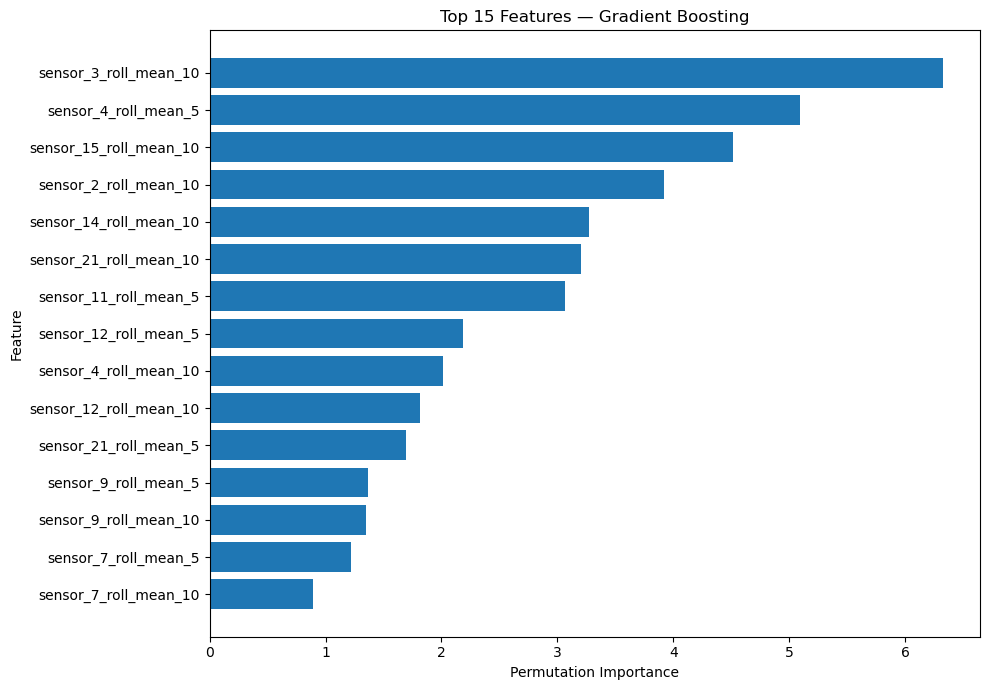

In [155]:
top_perm = perm_importance.head(15).sort_values()

plt.figure(figsize=(10, 7))

plt.barh(
    top_perm.index,
    top_perm.values
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features — Gradient Boosting")

plt.tight_layout()
plt.show()

In [157]:
dl_feature_cols = feature_cols

X_train_dl = train_data[dl_feature_cols]
y_train_dl = train_data["RUL"]

X_val_dl = val_data[dl_feature_cols]
y_val_dl = val_data["RUL"]

In [159]:
from sklearn.preprocessing import StandardScaler

dl_scaler = StandardScaler()

X_train_dl_scaled = dl_scaler.fit_transform(X_train_dl)
X_val_dl_scaled = dl_scaler.transform(X_val_dl)

In [161]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

mlp_model = Sequential([
    Input(shape=(X_train_dl_scaled.shape[1],)),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

mlp_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │           3,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,569 (53.00 KB)

 Trainable params: 13,569 (53.00 KB)

 Non-trainable params: 0 (0.00 B)

In [163]:
history = mlp_model.fit(
    X_train_dl_scaled,
    y_train_dl,
    validation_data=(X_val_dl_scaled, y_val_dl),
    epochs=50,
    batch_size=64,
    verbose=1
)

Epoch 1/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 5581.7729 - mae: 54.0362 - val_loss: 1411.1752 - val_mae: 28.4589
Epoch 2/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2206.1670 - mae: 34.5104 - val_loss: 1304.8463 - val_mae: 27.1188
Epoch 3/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2133.0537 - mae: 33.6120 - val_loss: 1288.8212 - val_mae: 26.5676
Epoch 4/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2067.2012 - mae: 32.9174 - val_loss: 1243.6021 - val_mae: 25.6867
Epoch 5/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2042.2892 - mae: 32.3637 - val_loss: 1214.6639 - val_mae: 25.6364
Epoch 6/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1990.1644 - mae: 31.9108 - val_loss: 1198.1382 - val_mae: 25.5560
Epoch 7/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2004.6069 - mae: 31.9404 - val_loss: 1211.7693 - val_mae: 25.4390
Epoch 8/50
258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1987.7001 - mae: 31.8066 - val_loss: 1191.8430 - val_mae: 

In [165]:
mlp_pred = mlp_model.predict(X_val_dl_scaled).flatten()

mlp_mae = mean_absolute_error(y_val_dl, mlp_pred)
mlp_rmse = np.sqrt(mean_squared_error(y_val_dl, mlp_pred))

print("MLP MAE:", mlp_mae)
print("MLP RMSE:", mlp_rmse)

127/127 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MLP MAE: 25.093132064842884
MLP RMSE: 34.62144645985422


In [167]:
train_data.head(10)

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_3_roll_std_5,sensor_11_roll_mean_10,sensor_9_roll_mean_10,sensor_4_roll_mean_10,sensor_12_roll_mean_10,sensor_14_roll_mean_10,sensor_7_roll_mean_10,sensor_15_roll_mean_10,sensor_21_roll_mean_10,sensor_3_roll_mean_10
193,2,2,0.0043,-0.0003,100.0,518.67,641.82,1587.05,1393.13,14.62,...,2.269813,47.085000,9053.015000,1392.205000,522.515000,8134.405000,554.650000,8.403600,23.433500,1585.445000
194,2,3,0.0018,0.0003,100.0,518.67,641.55,1588.32,1398.96,14.62,...,2.308946,47.130000,9053.423333,1394.456667,522.536667,8136.463333,554.813333,8.395800,23.430667,1586.403333
195,2,4,0.0035,-0.0004,100.0,518.67,641.68,1584.15,1396.08,14.62,...,2.196254,47.122500,9054.570000,1394.862500,522.525000,8137.457500,554.672500,8.397300,23.448675,1585.840000
196,2,5,0.0005,0.0004,100.0,518.67,641.73,1579.03,1402.52,14.62,...,3.590664,47.148000,9055.286000,1396.394000,522.474000,8137.300000,554.762000,8.395180,23.443620,1584.478000
197,2,6,-0.0010,0.0004,100.0,518.67,641.30,1577.50,1396.76,14.62,...,4.791080,47.131667,9055.083333,1396.455000,522.528333,8136.691667,554.798333,8.392650,23.440850,1583.315000
198,2,7,0.0001,-0.0002,100.0,518.67,642.03,1587.49,1400.65,14.62,...,4.882414,47.127143,9054.738571,1397.054286,522.472857,8136.640000,554.804286,8.392857,23.445271,1583.911429
199,2,8,0.0015,-0.0004,100.0,518.67,642.55,1590.41,1395.39,14.62,...,5.473535,47.136250,9054.873750,1396.846250,522.510000,8136.800000,554.785000,8.392012,23.444375,1584.723750
200,2,9,0.0017,-0.0004,100.0,518.67,641.98,1581.99,1395.01,14.62,...,5.515794,47.136667,9054.517778,1396.642222,522.497778,8137.743333,554.774444,8.391433,23.449167,1584.420000
201,2,10,-0.0045,0.0002,100.0,518.67,641.99,1586.37,1394.86,14.62,...,5.058352,47.144000,9054.954000,1396.464000,522.447000,8137.833000,554.760000,8.392110,23.464300,1584.615000
202,2,11,0.0006,0.0004,100.0,518.67,642.26,1589.21,1401.29,14.62,...,3.248273,47.172000,9054.803000,1397.465000,522.434000,8137.646000,554.777000,8.394940,23.457330,1585.152000


In [169]:
sequence_length = 30

In [171]:
import numpy as np

def create_sequences(data, feature_cols, target_col, sequence_length=30):
    X = []
    y = []

    for unit_id in data["unit"].unique():

        # Get one engine
        engine_data = data[data["unit"] == unit_id].sort_values("cycle")

        features = engine_data[feature_cols].values
        target = engine_data[target_col].values

        # Create sliding windows
        for i in range(sequence_length, len(engine_data) + 1):

            X.append(features[i-sequence_length:i])
            y.append(target[i-1])

    return np.array(X), np.array(y)

In [173]:
sequence_length = 30

X_train_seq, y_train_seq = create_sequences(
    train_data,
    dl_feature_cols,
    "RUL",
    sequence_length
)

print("X_train_seq shape:", X_train_seq.shape)
print("y_train_seq shape:", y_train_seq.shape)

X_train_seq shape: (14161, 30, 24)
y_train_seq shape: (14161,)


In [175]:
X_val_seq, y_val_seq = create_sequences(
    val_data,
    dl_feature_cols,
    "RUL",
    sequence_length
)

print("X_val_seq shape:", X_val_seq.shape)
print("y_val_seq shape:", y_val_seq.shape)

X_val_seq shape: (3470, 30, 24)
y_val_seq shape: (3470,)


In [177]:
engine_1 = train_data[train_data["unit"] == 1].sort_values("cycle")

print(engine_1[["unit", "cycle", "RUL"]].head())
print()
print(engine_1[["unit", "cycle", "RUL"]].tail())

Empty DataFrame
Columns: [unit, cycle, RUL]
Index: []

Empty DataFrame
Columns: [unit, cycle, RUL]
Index: []


In [179]:
train_data["unit"].unique()

array([  2,   3,   4,   6,   7,   8,   9,  10,  12,  14,  15,  16,  17,
        18,  20,  21,  22,  24,  25,  26,  27,  28,  29,  30,  33,  35,
        36,  37,  38,  39,  41,  42,  43,  44,  47,  48,  49,  50,  51,
        52,  53,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  72,  73,  75,  76,  79,  80,  82,  83,
        85,  86,  87,  88,  89,  90,  92,  93,  94,  95,  96,  97,  98,
        99, 100], dtype=int64)

In [181]:
val_data["unit"].unique()

array([ 1,  5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78,
       81, 84, 91], dtype=int64)

In [183]:
first_train_engine = train_data["unit"].iloc[0]

print("Engine:", first_train_engine)

train_data[
    train_data["unit"] == first_train_engine
][["unit", "cycle", "RUL"]].head(30)

Engine: 2


,unit,cycle,RUL
193,2,2,285
194,2,3,284
195,2,4,283
196,2,5,282
197,2,6,281
198,2,7,280
199,2,8,279
200,2,9,278
201,2,10,277
202,2,11,276


In [187]:
engine_2 = train_data[train_data["unit"] == 2].sort_values("cycle")

print(engine_2[["unit", "cycle", "RUL"]].head(30))

     unit  cycle  RUL
193     2      2  285
194     2      3  284
195     2      4  283
196     2      5  282
197     2      6  281
198     2      7  280
199     2      8  279
200     2      9  278
201     2     10  277
202     2     11  276
203     2     12  275
204     2     13  274
205     2     14  273
206     2     15  272
207     2     16  271
208     2     17  270
209     2     18  269
210     2     19  268
211     2     20  267
212     2     21  266
213     2     22  265
214     2     23  264
215     2     24  263
216     2     25  262
217     2     26  261
218     2     27  260
219     2     28  259
220     2     29  258
221     2     30  257
222     2     31  256


In [189]:
print(engine_2[["unit", "cycle", "RUL"]].tail())

     unit  cycle  RUL
474     2    283    4
475     2    284    3
476     2    285    2
477     2    286    1
478     2    287    0


In [191]:
print("First sequence shape:", X_train_seq[0].shape)
print("First sequence target:", y_train_seq[0])

First sequence shape: (30, 24)
First sequence target: 256


In [193]:
print(
    engine_2[["cycle", "RUL"]].head(30).tail(1)
)

     cycle  RUL
222     31  256


In [195]:
y_train_seq[0]

256

In [197]:
from sklearn.preprocessing import StandardScaler

scaler_lstm = StandardScaler()

# Flatten: (samples, timesteps, features)
n_train, timesteps, n_features = X_train_seq.shape

X_train_2d = X_train_seq.reshape(-1, n_features)

# Fit ONLY on training data
X_train_2d_scaled = scaler_lstm.fit_transform(X_train_2d)

# Reshape back to 3D
X_train_lstm = X_train_2d_scaled.reshape(
    n_train, timesteps, n_features
)

# Validation
n_val = X_val_seq.shape[0]

X_val_2d = X_val_seq.reshape(-1, n_features)
X_val_2d_scaled = scaler_lstm.transform(X_val_2d)

X_val_lstm = X_val_2d_scaled.reshape(
    n_val, timesteps, n_features
)

print("Training:", X_train_lstm.shape)
print("Validation:", X_val_lstm.shape)

Training: (14161, 30, 24)
Validation: (3470, 30, 24)


In [199]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

lstm_model = Sequential([
    Input(shape=(timesteps, n_features)),

    LSTM(64),
    Dropout(0.2),

    Dense(32, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          22,784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,897 (97.25 KB)

 Trainable params: 24,897 (97.25 KB)

 Non-trainable params: 0 (0.00 B)

In [201]:
history_lstm = lstm_model.fit(
    X_train_lstm,
    y_train_seq,
    validation_data=(X_val_lstm, y_val_seq),
    epochs=30,
    batch_size=64,
    verbose=1
)

Epoch 1/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - loss: 8047.6045 - mae: 67.8789 - val_loss: 2650.9712 - val_mae: 35.3355
Epoch 2/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - loss: 1914.9553 - mae: 28.6534 - val_loss: 803.9591 - val_mae: 20.1104
Epoch 3/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - loss: 1255.2524 - mae: 23.6558 - val_loss: 688.7338 - val_mae: 19.4106
Epoch 4/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - loss: 1102.6588 - mae: 22.2883 - val_loss: 594.7483 - val_mae: 17.5006
Epoch 5/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 969.1208 - mae: 21.0408 - val_loss: 611.6904 - val_mae: 17.7096
Epoch 6/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - loss: 882.0266 - mae: 20.1931 - val_loss: 553.9589 - val_mae: 16.0961
Epoch 7/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - loss: 833.1441 - mae: 19.5159 - val_loss: 624.5303 - val_mae: 17.4644
Epoch 8/30
222/222 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - loss: 756.4183 - mae: 18.7244 - val_loss: 591.1937 - val_mae: 17

In [203]:
lstm_pred = lstm_model.predict(X_val_lstm).flatten()

lstm_mae = mean_absolute_error(y_val_seq, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_val_seq, lstm_pred))

print("LSTM MAE:", lstm_mae)
print("LSTM RMSE:", lstm_rmse)

109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
LSTM MAE: 20.481754160477035
LSTM RMSE: 30.517539441329518


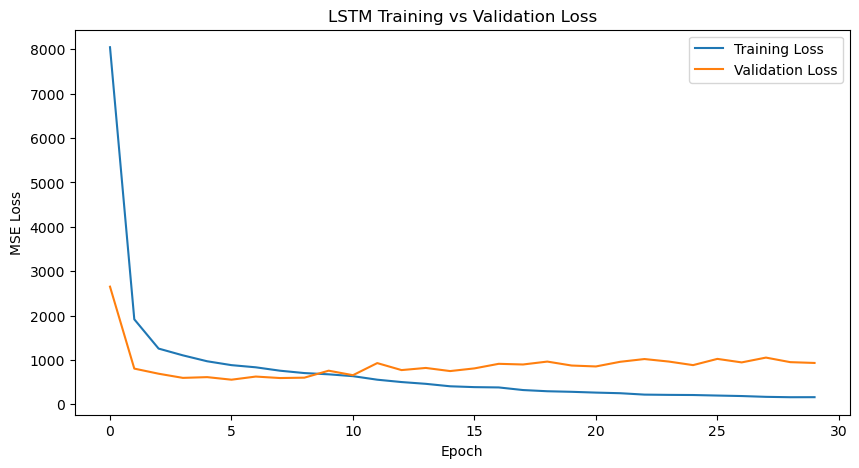

In [205]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history_lstm.history["loss"], label="Training Loss")
plt.plot(history_lstm.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training vs Validation Loss")
plt.legend()
plt.show()

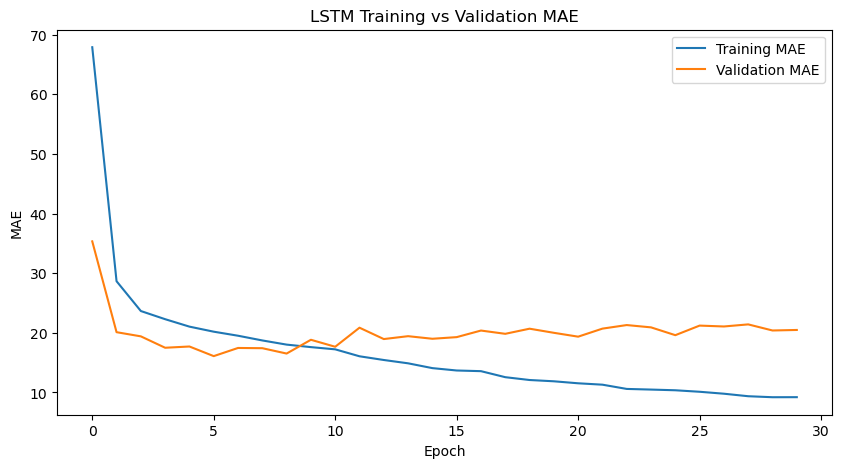

In [207]:
plt.figure(figsize=(10, 5))

plt.plot(history_lstm.history["mae"], label="Training MAE")
plt.plot(history_lstm.history["val_mae"], label="Validation MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("LSTM Training vs Validation MAE")
plt.legend()
plt.show()

In [209]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [211]:
history_lstm = lstm_model.fit(
    X_train_lstm,
    y_train_seq,
    validation_data=(X_val_lstm, y_val_seq),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 157.5594 - mae: 9.0884 - val_loss: 957.9576 - val_mae: 20.6005
Epoch 2/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 147.6092 - mae: 8.7645 - val_loss: 1179.3824 - val_mae: 22.4419
Epoch 3/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 149.8622 - mae: 8.8599 - val_loss: 988.4980 - val_mae: 20.8712
Epoch 4/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 143.7041 - mae: 8.7040 - val_loss: 1011.5986 - val_mae: 21.3667
Epoch 5/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 133.2941 - mae: 8.3801 - val_loss: 1020.3843 - val_mae: 21.2219
Epoch 6/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 130.3279 - mae: 8.3037 - val_loss: 946.5254 - val_mae: 20.6487
Epoch 7/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 133.9919 - mae: 8.3718 - val_loss: 987.5421 - val_mae: 20.7588
Epoch 8/50
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 121.8343 - mae: 8.0618 - val_loss: 1104.4795 - val_mae: 21.8391
Epoc

In [213]:
lstm_pred = lstm_model.predict(X_val_lstm).flatten()

lstm_mae = mean_absolute_error(y_val_seq, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_val_seq, lstm_pred))

print("LSTM MAE:", lstm_mae)
print("LSTM RMSE:", lstm_rmse)

109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
LSTM MAE: 20.64868862728564
LSTM RMSE: 30.76565301869021


In [215]:
best_epoch = np.argmin(history_lstm.history["val_loss"]) + 1

print("Best epoch:", best_epoch)
print("Best validation loss:", min(history_lstm.history["val_loss"]))
print("Best validation MAE:", min(history_lstm.history["val_mae"]))

Best epoch: 6
Best validation loss: 946.525390625
Best validation MAE: 20.60048484802246


In [217]:
def prepare_lstm_sequences(sequence_length):

    X_train_seq, y_train_seq = create_sequences(
        train_data,
        dl_feature_cols,
        "RUL",
        sequence_length
    )

    X_val_seq, y_val_seq = create_sequences(
        val_data,
        dl_feature_cols,
        "RUL",
        sequence_length
    )

    # Scale using training data only
    n_train, timesteps, n_features = X_train_seq.shape

    scaler = StandardScaler()

    X_train_2d = X_train_seq.reshape(-1, n_features)
    X_train_scaled = scaler.fit_transform(X_train_2d)

    X_train_lstm = X_train_scaled.reshape(
        n_train, timesteps, n_features
    )

    # Validation
    n_val = X_val_seq.shape[0]

    X_val_2d = X_val_seq.reshape(-1, n_features)
    X_val_scaled = scaler.transform(X_val_2d)

    X_val_lstm = X_val_scaled.reshape(
        n_val, timesteps, n_features
    )

    return (
        X_train_lstm,
        y_train_seq,
        X_val_lstm,
        y_val_seq
    )

In [219]:
X_train_15, y_train_15, X_val_15, y_val_15 = prepare_lstm_sequences(15)

print("Train:", X_train_15.shape)
print("Validation:", X_val_15.shape)

Train: (15361, 15, 24)
Validation: (3770, 15, 24)


In [221]:
X_train_50, y_train_50, X_val_50, y_val_50 = prepare_lstm_sequences(50)

print("Train:", X_train_50.shape)
print("Validation:", X_val_50.shape)

Train: (12561, 50, 24)
Validation: (3070, 50, 24)


In [223]:
def build_lstm(timesteps, n_features):

    model = Sequential([
        Input(shape=(timesteps, n_features)),
        LSTM(64),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    return model

In [225]:
lstm_15 = build_lstm(15, 24)

history_15 = lstm_15.fit(
    X_train_15,
    y_train_15,
    validation_data=(X_val_15, y_val_15),
    epochs=30,
    batch_size=64,
    verbose=1
)

Epoch 1/30
241/241 ━━━━━━━━━━━━━━━━━━━━ 13s 25ms/step - loss: 7139.2642 - mae: 61.5790 - val_loss: 1491.9677 - val_mae: 27.0304
Epoch 2/30
241/241 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - loss: 1740.7871 - mae: 28.8866 - val_loss: 1076.0341 - val_mae: 24.2181
Epoch 3/30
241/241 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - loss: 1593.2375 - mae: 27.9635 - val_loss: 975.0560 - val_mae: 22.7648
Epoch 4/30
241/241 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - loss: 1553.0874 - mae: 27.7000 - val_loss: 977.6620 - val_mae: 23.0880
Epoch 5/30
241/241 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - loss: 1485.0514 - mae: 27.1349 - val_loss: 951.8918 - val_mae: 22.5850
Epoch 6/30
241/241 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - loss: 1425.1886 - mae: 26.5963 - val_loss: 927.3152 - val_mae: 22.1604
Epoch 7/30
241/241 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - loss: 1361.7958 - mae: 25.9685 - val_loss: 896.1402 - val_mae: 21.4148
Epoch 8/30
241/241 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - loss: 1377.4152 - mae: 26.0764 - val_loss: 935.8446 - 

In [227]:
pred_15 = lstm_15.predict(X_val_15).flatten()

mae_15 = mean_absolute_error(y_val_15, pred_15)
rmse_15 = np.sqrt(mean_squared_error(y_val_15, pred_15))

print("15-cycle LSTM MAE:", mae_15)
print("15-cycle LSTM RMSE:", rmse_15)

118/118 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step
15-cycle LSTM MAE: 25.791367108815546
15-cycle LSTM RMSE: 36.89133907551658


In [229]:
lstm_50 = build_lstm(50, 24)

history_50 = lstm_50.fit(
    X_train_50,
    y_train_50,
    validation_data=(X_val_50, y_val_50),
    epochs=30,
    batch_size=64,
    verbose=1
)

Epoch 1/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 16s 62ms/step - loss: 6046.6475 - mae: 56.8401 - val_loss: 1355.3687 - val_mae: 24.8740
Epoch 2/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - loss: 1355.0839 - mae: 24.2679 - val_loss: 578.2947 - val_mae: 16.8184
Epoch 3/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 11s 58ms/step - loss: 939.4447 - mae: 20.1155 - val_loss: 409.5187 - val_mae: 14.6530
Epoch 4/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step - loss: 713.0850 - mae: 17.5655 - val_loss: 413.0779 - val_mae: 13.8843
Epoch 5/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - loss: 638.7055 - mae: 16.7445 - val_loss: 402.5972 - val_mae: 14.2393
Epoch 6/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step - loss: 548.7153 - mae: 15.6291 - val_loss: 418.9841 - val_mae: 14.3871
Epoch 7/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - loss: 501.7627 - mae: 14.9451 - val_loss: 491.1999 - val_mae: 15.2119
Epoch 8/30
197/197 ━━━━━━━━━━━━━━━━━━━━ 12s 60ms/step - loss: 454.8970 - mae: 14.3094 - val_loss: 421.6449 - val_ma

In [231]:
pred_50 = lstm_50.predict(X_val_50).flatten()

mae_50 = mean_absolute_error(y_val_50, pred_50)
rmse_50 = np.sqrt(mean_squared_error(y_val_50, pred_50))

print("50-cycle LSTM MAE:", mae_50)
print("50-cycle LSTM RMSE:", rmse_50)

96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step
50-cycle LSTM MAE: 17.05425426315407
50-cycle LSTM RMSE: 24.721537474629944


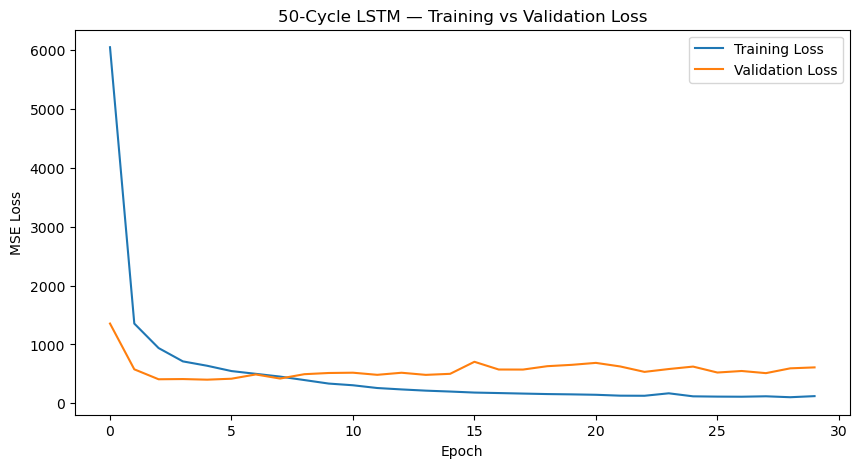

In [233]:
plt.figure(figsize=(10, 5))

plt.plot(history_50.history["loss"], label="Training Loss")
plt.plot(history_50.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("50-Cycle LSTM — Training vs Validation Loss")
plt.legend()
plt.show()

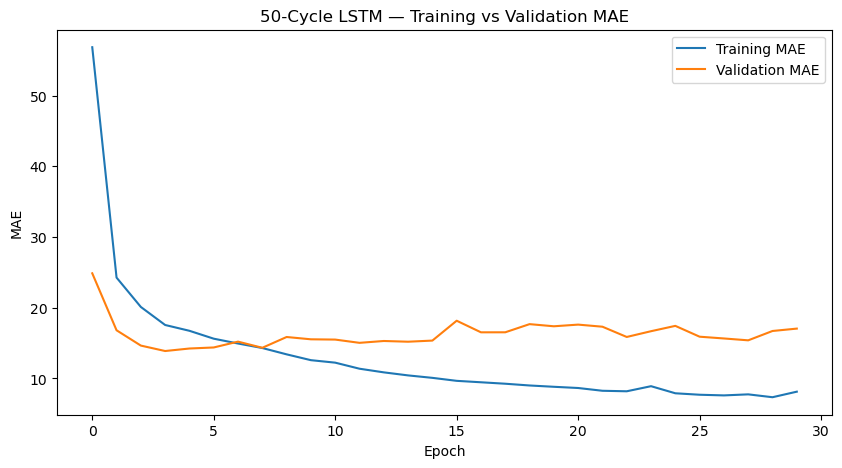

In [235]:
plt.figure(figsize=(10, 5))

plt.plot(history_50.history["mae"], label="Training MAE")
plt.plot(history_50.history["val_mae"], label="Validation MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("50-Cycle LSTM — Training vs Validation MAE")
plt.legend()
plt.show()

In [237]:
best_epoch_50 = np.argmin(history_50.history["val_loss"]) + 1

print("Best epoch:", best_epoch_50)
print("Best validation loss:", min(history_50.history["val_loss"]))
print("Best validation MAE:", min(history_50.history["val_mae"]))

Best epoch: 5
Best validation loss: 402.5971984863281
Best validation MAE: 13.884334564208984


In [239]:
lstm_50_es = build_lstm(50, 24)

In [241]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping_50 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [243]:
history_50_es = lstm_50_es.fit(
    X_train_50,
    y_train_50,
    validation_data=(X_val_50, y_val_50),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping_50],
    verbose=1
)

Epoch 1/50
197/197 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - loss: 5664.2651 - mae: 54.1350 - val_loss: 1103.6873 - val_mae: 22.9544
Epoch 2/50
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 1246.2965 - mae: 23.3612 - val_loss: 457.7445 - val_mae: 15.3106
Epoch 3/50
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 847.3357 - mae: 19.0265 - val_loss: 392.7598 - val_mae: 13.7240
Epoch 4/50
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 679.0928 - mae: 17.1849 - val_loss: 477.0555 - val_mae: 15.5987
Epoch 5/50
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 579.8015 - mae: 16.1956 - val_loss: 435.6967 - val_mae: 14.5688
Epoch 6/50
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 539.9493 - mae: 15.5261 - val_loss: 477.3367 - val_mae: 15.2893
Epoch 7/50
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 472.1059 - mae: 14.6825 - val_loss: 408.4561 - val_mae: 14.0120
Epoch 8/50
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 427.2654 - mae: 14.0768 - val_loss: 489.3777 - val_mae: 14.87

In [245]:
pred_50_es = lstm_50_es.predict(X_val_50).flatten()

mae_50_es = mean_absolute_error(y_val_50, pred_50_es)
rmse_50_es = np.sqrt(mean_squared_error(y_val_50, pred_50_es))

print("50-cycle LSTM + EarlyStopping MAE:", mae_50_es)
print("50-cycle LSTM + EarlyStopping RMSE:", rmse_50_es)

96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
50-cycle LSTM + EarlyStopping MAE: 13.72399438763286
50-cycle LSTM + EarlyStopping RMSE: 19.81816758699689


In [247]:
test_path = "../data/raw/test_FD001.txt"
rul_path = "../data/raw/RUL_FD001.txt"

test_df = pd.read_csv(
    test_path,
    sep=r"\s+",
    header=None
)

test_df.columns = columns

rul_df = pd.read_csv(
    rul_path,
    header=None
)

test_rul = rul_df[0].values

print("Test shape:", test_df.shape)
print("RUL shape:", test_rul.shape)

Test shape: (13096, 26)
RUL shape: (100,)


In [251]:
test_lengths = (
    test_df.groupby("unit")["cycle"]
    .max()
)

print(test_lengths.describe())
print("Minimum cycles:", test_lengths.min())
print("Maximum cycles:", test_lengths.max())
print("Engines with < 50 cycles:", (test_lengths < 50).sum())

count    100.000000
mean     130.960000
std       53.593479
min       31.000000
25%       88.750000
50%      133.500000
75%      164.250000
max      303.000000
Name: cycle, dtype: float64
Minimum cycles: 31
Maximum cycles: 303
Engines with < 50 cycles: 7


In [253]:
test_sequences = []

for unit_id in sorted(test_df["unit"].unique()):

    engine_data = (
        test_df[test_df["unit"] == unit_id]
        .sort_values("cycle")
    )

    engine_features = engine_data[dl_feature_cols].values

    if len(engine_features) >= 50:
        last_50 = engine_features[-50:]

    else:
        padding_size = 50 - len(engine_features)

        padding = np.repeat(
            engine_features[0:1],
            padding_size,
            axis=0
        )

        last_50 = np.vstack([
            padding,
            engine_features
        ])

    test_sequences.append(last_50)

X_test_seq = np.array(test_sequences)

print("X_test_seq shape:", X_test_seq.shape)

X_test_seq shape: (100, 50, 24)


In [257]:
X_train_50_raw, _ = create_sequences(
    train_data,
    dl_feature_cols,
    "RUL",
    50
)

print("Training sequence shape:", X_train_50_raw.shape)

Training sequence shape: (12561, 50, 24)


In [259]:
final_scaler = StandardScaler()

n_train, timesteps, n_features = X_train_50_raw.shape

X_train_50_2d = X_train_50_raw.reshape(
    -1, n_features
)

final_scaler.fit(X_train_50_2d)

StandardScaler()

In [261]:
X_test_2d = X_test_seq.reshape(
    -1, n_features
)

X_test_scaled = final_scaler.transform(X_test_2d)

X_test_lstm = X_test_scaled.reshape(
    X_test_seq.shape
)

print("X_test_lstm shape:", X_test_lstm.shape)

X_test_lstm shape: (100, 50, 24)


In [263]:
test_pred = lstm_50_es.predict(X_test_lstm).flatten()

print("Number of predictions:", len(test_pred))
print("First 10 predictions:")
print(test_pred[:10])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Number of predictions: 100
First 10 predictions:
[138.29324  132.53033   47.159004  71.102684  77.45379  104.28079
 124.06742   65.55273  142.97212   62.896896]


In [265]:
test_mae = mean_absolute_error(
    test_rul,
    test_pred
)

test_rmse = np.sqrt(
    mean_squared_error(
        test_rul,
        test_pred
    )
)

print("Final Test MAE:", test_mae)
print("Final Test RMSE:", test_rmse)

Final Test MAE: 16.95480251789093
Final Test RMSE: 23.67199113998199


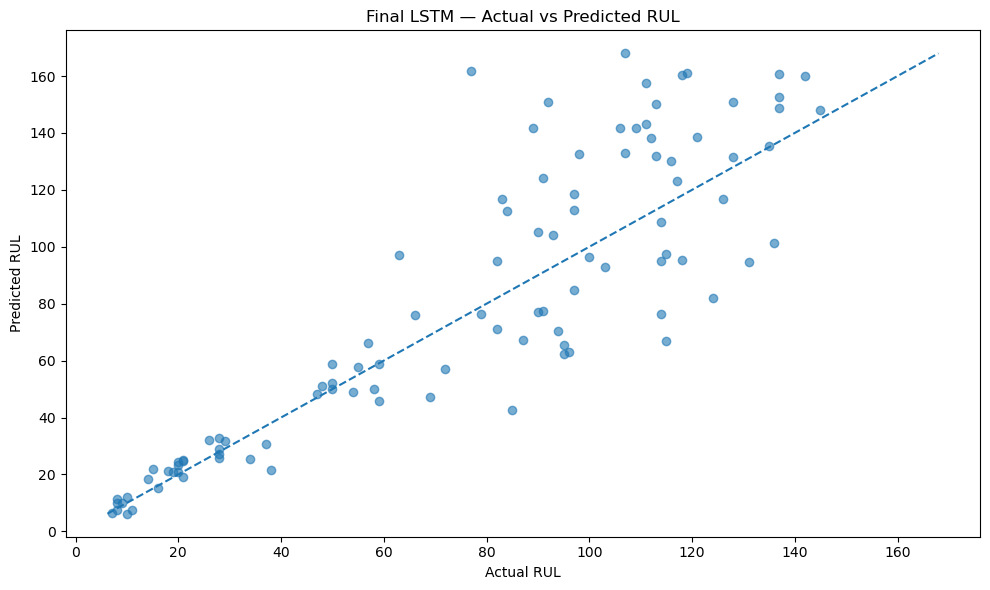

In [267]:
plt.figure(figsize=(10, 6))

plt.scatter(test_rul, test_pred, alpha=0.6)

min_val = min(test_rul.min(), test_pred.min())
max_val = max(test_rul.max(), test_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Final LSTM — Actual vs Predicted RUL")
plt.tight_layout()
plt.show()

In [271]:
errors = np.abs(test_rul - test_pred)

error_analysis = pd.DataFrame({
    "Engine": np.arange(1, 101),
    "Actual_RUL": test_rul,
    "Predicted_RUL": test_pred,
    "Absolute_Error": errors
})

error_analysis = error_analysis.sort_values(
    "Absolute_Error",
    ascending=False
)

error_analysis.head(10)

,Engine,Actual_RUL,Predicted_RUL,Absolute_Error
66,67,77,161.796066,84.796066
77,78,107,167.963806,60.963806
47,48,92,150.731750,58.731750
85,86,89,141.589447,52.589447
29,30,115,66.909424,48.090576
21,22,111,157.389542,46.389542
70,71,118,160.305298,42.305298
92,93,85,42.723595,42.276405
11,12,124,81.989983,42.010017
25,26,119,160.906281,41.906281


In [273]:
error_analysis["Error"] = (
    error_analysis["Predicted_RUL"]
    - error_analysis["Actual_RUL"]
)

print("Mean Error:", error_analysis["Error"].mean())

Mean Error: 4.387849802970886


In [277]:
#Mean Error > 0
#→ model tends to overpredict RUL

#Mean Error < 0
#→ model tends to underpredict RUL

#Mean Error ≈ 0
#→ little overall systematic bias


In [279]:
model_path = "../models/rul_lstm_50.keras"

lstm_50_es.save(model_path)

print("Model saved:", model_path)

Model saved: ../models/rul_lstm_50.keras


In [281]:
import joblib

scaler_path = "../models/rul_scaler.pkl"

joblib.dump(
    final_scaler,
    scaler_path
)

print("Scaler saved:", scaler_path)

Scaler saved: ../models/rul_scaler.pkl


In [1]:
import os 
[rint(os.getcwd())

SyntaxError: incomplete input (3098193625.py, line 2)

In [3]:
import os
print(os.getcwd())

C:\Users\hp\predictive-maintenance\notebooks


In [5]:

import os

project_dir = os.path.dirname(os.getcwd())

print("Project folder:", project_dir)
print("\nFiles in models folder:")

models_dir = os.path.join(project_dir, "models")

if os.path.exists(models_dir):
    print(os.listdir(models_dir))
else:
    print("Models folder not found.")


Project folder: C:\Users\hp\predictive-maintenance

Files in models folder:
['rul_lstm_50.keras', 'rul_scaler.pkl']


In [9]:
dl_feature_cols = (
    ["setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

print("Number of features:", len(dl_feature_cols))
print("Feature order:", dl_feature_cols)

Number of features: 24
Feature order: ['setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [3]:
dl_feature_cols = (
    ["setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

print(dl_feature_cols)

['setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']
